# 05_DDPM — 셀별 코드 해설 노트북 (Python 초보용)

이 노트북은 원본 `05_DDPM.ipynb`와 **코드가 완전히 같습니다.** `# 1`, `# 2` … 번호가 붙은 코드 셀 **바로 위에** "[셀 # N] 코드 설명" 칸이 하나씩 추가되었습니다. 설명은 *한 줄 요약 → 코드 흐름 → Python 초보 포인트* 순서입니다.

**DDPM(디퓨전 모델)을 한 문장으로:** 깨끗한 그림에 잡음을 조금씩 섞어 완전한 잡음으로 만드는 과정을 정해 두고, 신경망에게 **"이 그림에 섞인 잡음이 무엇인지 맞혀 봐"** 를 학습시킨 다음, 완전한 잡음에서 출발해 예측한 잡음을 조금씩 빼 나가며 새 그림을 만들어 내는 모델입니다.

**두 방향의 과정**

| 이름 | 방향 | 누가 하나 | 코드에서 |
|---|---|---|---|
| Forward (정방향) | 그림 → 잡음 | 정해진 수식 (학습 없음) | `q_sample` (7번 셀) |
| Reverse (역방향) | 잡음 → 그림 | 학습된 신경망(U-Net) | `p_sample` (10번 셀) |

**자주 나오는 기호**

| 기호/이름 | 쉬운 뜻 |
|---|---|
| `t` (타임스텝) | 잡음이 섞인 정도를 나타내는 단계 번호. 0이면 거의 원본, 클수록 잡음이 많음 |
| `T` / `timesteps` | 전체 단계 수. 이 노트북에서는 300 |
| `x_0` / `x_start` | 깨끗한 원본 그림 |
| `x_t` | t단계까지 잡음이 섞인 그림 |
| `beta` (β) | 각 단계에서 섞는 잡음의 양 |
| `alpha` (α) | `1 - beta`. 각 단계에서 남는 원본의 비율 |
| `alphas_cumprod` (ᾱ, 알파 바) | 처음부터 t단계까지 남은 원본의 누적 비율 |
| epsilon (ε) / `noise` | 섞는 잡음 그 자체 |

**이 노트북의 구성:** 2~5번 셀은 신경망(U-Net)의 부품과 본체, 6~8번 셀은 디퓨전 수식, 9번은 데이터, 10번은 그림 생성 함수, 11~12번은 학습, 13~14번은 결과 확인입니다. 2~5번 셀은 이 과정에서 가장 어려운 부분이니, 처음에는 "무엇을 하는 부품인지"만 파악하고 넘어가도 좋습니다.

**미리 알아둘 점:** 이 노트북에는 다른 노트북과 달리 패키지 자동 설치 셀이 없습니다. 1번 셀에서 `ModuleNotFoundError`가 나면 새 셀에 `%pip install einops datasets` 를 실행한 뒤 다시 시도하세요.

---

# **DDPM — 학습/추론/시각화**

**DDPM (Denoising Diffusion Probabilistic Models)** 을 직접 구현하면서 구조를 이해하는 것을 목표로 합니다.

## 학습 목표
- DDPM의 원리를 이해한다.
- Forward / Reverse diffusion 을 이해하고 Training과 Sampling 과정을 구현한다.

---

### 구성 개요
1. Diffusion / DDPM 개념 요약
2. 실험 환경 및 기본 설정
3. U-Net 기반 노이즈 예측 신경망 구현
4. Forward Diffusion Process 정의 ($q$)
5. Reverse Diffusion Process 정의 ($p$)
6. Fashion-MNIST 데이터셋 로드 및 전처리
7. 학습 루프 구현
8. 샘플링 및 시각화 (이미지 + GIF)


## 1. Diffusion / DDPM 개념 요약

### 1.1 생성 모델 관점

- 생성 모델(generative model)은 **데이터 분포 $p_{data}(x)$** 를 학습해서, 학습 후에는 샘플링으로 새로운 데이터를 생성할 수 있는 모델입니다.
- 예: GAN, VAE, Autoregressive model, Flow-based model, Diffusion model 등

### 1.2 Diffusion 모델의 아이디어 (고수준)

1. **Forward Diffusion (noising)** - 깨끗한 이미지 $x_0$ 에 **점진적으로 가우시안 노이즈를 추가**해서 $x_1, x_2, \dots, x_T$ 를 만듭니다.
   - $T$ 가 충분히 크면, $x_T$ 는 거의 **표준 정규분포와 비슷한 pure noise** 가 됩니다.
   - 이 과정은 **고정된 마르코프 체인** $q(x_t \mid x_{t-1})$ 으로 정의됩니다.

2. **Reverse Diffusion (denoising)** - 우리가 학습하고 싶은 것은 반대로 **노이즈에서 시작해서 점점 이미지를 되살리는 과정**입니다.
   - $p_\theta(x_{t-1} \mid x_t)$ 를 신경망으로 근사해서, $x_T \sim \mathcal{N}(0, I)$ 에서 시작해 $x_0$ 를 샘플링할 수 있게 합니다.

3. **DDPM의 핵심 포인트** - Forward process는 **닫힌형태(analytic form)** 를 가지도록 설계되어, $q(x_t \mid x_0)$ 를 한 번에 샘플링할 수 있습니다.
   - 학습 시에는 $x_0$ 와 $t$ 를 샘플링한 뒤, $x_t$ 를 계산하고, 네트워크가 **노이즈 $\epsilon$** 을 예측하도록 만듭니다.
   - 손실 함수는 보통 **예측 노이즈와 실제 노이즈의 $L_2$ 또는 Huber loss** 로 정의합니다.

이제부터는 이 개념을 실제 코드로 구현해 봅니다.

## 2. 환경 설정 및 기본 Import

- PyTorch, torchvision, einops, datasets, matplotlib 등을 사용합니다.
- 아래 셀은 GPU 사용 가능 여부를 확인하고, 필요한 라이브러리를 import 합니다.


### [셀 # 1] 코드 설명

**한 줄 요약:** 이후 셀에서 쓸 도구를 모두 불러오고, 계산에 쓸 장치(GPU/CPU)를 정합니다.

**코드 흐름 — 불러오는 도구들**

| 코드 | 용도 |
|---|---|
| `import math` | 수학 함수(로그 등) |
| `from functools import partial` | 함수의 인자 일부를 미리 채워 두는 도구(3, 5번 셀) |
| `from pathlib import Path` | 폴더/파일 경로를 다루는 도구(11번 셀) |
| `import torch`, `torch.nn as nn`, `torch.nn.functional as F` | PyTorch 본체, 신경망 층, 함수형 도구 |
| `from torch.utils.data import DataLoader` | 데이터를 묶음으로 꺼내는 도구 |
| `from torchvision import transforms` | 이미지 전처리 |
| `from torchvision.utils import save_image` | 텐서를 그림 파일로 저장 |
| `from einops import rearrange, reduce` / `Rearrange` | 텐서 모양을 `"b c h w -> ..."` 같은 글자로 바꾸는 도구 |
| `from datasets import load_dataset` | Hugging Face의 데이터셋 내려받기 도구 |
| `numpy as np`, `matplotlib.pyplot as plt` | 숫자 배열 계산, 그림 그리기 |
| `from tqdm.auto import tqdm` | 반복문의 진행 막대 표시 |

마지막 두 줄: `device = "cuda" if torch.cuda.is_available() else "cpu"` — GPU가 있으면 `"cuda"`, 없으면 `"cpu"` 문자열을 `device`에 담고 출력합니다.

**Python 초보 포인트**

- `import A` 는 A 전체를, `from A import B` 는 A 안의 B만 가져옵니다. `as`는 짧은 별명을 붙입니다.
- `A if 조건 else B` : 조건이 참이면 A, 거짓이면 B.
- `f"Using device: {device}"` : f-string. 중괄호 안의 변수 값이 문자열에 들어갑니다.
- 여기서 불러온 것 중 일부(`reduce`, `partial` 등)는 한참 뒤의 셀에서 쓰입니다. 노트북 맨 위에 import를 모아 두는 것이 일반적인 습관입니다.

In [1]:
# 1
# 유틸리티 및 함수형 프로그래밍 관련
import math
from functools import partial
from pathlib import Path   # 파일 및 디렉토리 경로 관리

# PyTorch 핵심 라이브러리
import torch
import torch.nn as nn            # 신경망 레이어 구성 (Conv2d, Linear 등)
import torch.nn.functional as F   # 활성화 함수 및 손실 함수

# 데이터 로딩 및 이미지 처리
from torch.utils.data import DataLoader
from torchvision import transforms      # 이미지 전처리 (Resize, ToTensor 등)
from torchvision.utils import save_image # 결과 이미지 저장

# 텐서 차원 조작 (가독성 높은 텐서 변환)
from einops import rearrange, reduce
from einops.layers.torch import Rearrange # 모델 레이어 내 차원 재구성

# 데이터셋 불러오기 및 시각화/수치 계산
from datasets import load_dataset # 데이터셋 로드
import numpy as np
import matplotlib.pyplot as plt   # 학습 곡선 및 이미지 시각화
from tqdm.auto import tqdm        # 학습 진행률 표시바

# 연산 장치 설정 (GPU 가속 여부 확인)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")


Using device: cuda


## 3. U-Net 구현을 위한 Helper 함수들

DDPM에서 사용할 U-Net 구조를 구현하기 위해 아래와 같은 helper 함수/클래스를 사용합니다.

- `exists`, `default`: 인자 존재 여부/기본값 처리용 유틸리티
- `num_to_groups`: 전체 개수를 mini-batch 그룹 형태로 나누기
- `Residual`: 잔차 연결(residual connection)을 감싸는 래퍼
- `Upsample` / `Downsample`: 이미지 해상도를 2배 업/다운샘플링하는 모듈


### [셀 # 2] 코드 설명

**한 줄 요약:** U-Net을 만들 때 반복해서 쓸 작은 도우미들을 준비합니다 — 값 확인 함수 3개, 잔차 연결 포장지 1개, 크기를 키우고 줄이는 블록 2개.

**코드 흐름**

1. `exists(x)` — `x`가 `None`이 아니면 `True`를 돌려줍니다. "값이 들어 있는가?"를 읽기 쉽게 쓰려는 함수입니다.
2. `default(val, d)` — `val`이 있으면 `val`을, 없으면 기본값 `d`를 돌려줍니다. `d`가 함수이면(`callable(d)`) 그 함수를 실행한 결과를 돌려줍니다.
3. `num_to_groups(num, divisor)` — 개수를 묶음으로 나눕니다. 예: `num_to_groups(10, 4)` → `[4, 4, 2]`
   - `groups = num // divisor` : 몫(꽉 찬 묶음 수) → 2
   - `remainder = num % divisor` : 나머지 → 2
   - `arr = [divisor] * groups` : `[4, 4]`
   - 나머지가 있으면 `arr.append(remainder)` → `[4, 4, 2]`
4. `class Residual(nn.Module)` — 어떤 층 `fn`을 감싸서 `fn(x) + x`를 돌려주는 포장지입니다. 계산 결과에 입력을 그대로 더하는 **잔차 연결**로, 층이 깊어도 정보가 사라지지 않게 합니다.
5. `Upsample(dim, dim_out=None)` — 가로세로를 **2배로** 키우는 블록을 만들어 돌려줍니다. `nn.Upsample(scale_factor=2, mode="nearest")`로 픽셀을 복사해 키운 뒤 3×3 Conv로 다듬습니다.
6. `Downsample(dim, dim_out=None)` — 가로세로를 **절반으로** 줄이는 블록입니다.
   - `Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2)` : 2×2 픽셀 4개를 버리지 않고 **채널 방향으로 옮겨 쌓습니다.** `(B, C, 28, 28)` → `(B, 4C, 14, 14)`. 정보 손실이 없습니다.
   - `nn.Conv2d(dim * 4, default(dim_out, dim), 1)` : 1×1 Conv로 채널 수를 원하는 값으로 맞춥니다.

**Python 초보 포인트**

- `x is not None` : "x가 비어 있지 않다". `None`은 "값 없음"을 뜻하는 특별한 값입니다.
- `//` 는 몫, `%` 는 나머지입니다. `10 // 4` → 2, `10 % 4` → 2
- `[4] * 2` → `[4, 4]`. 리스트에 숫자를 곱하면 그만큼 반복됩니다.
- `def forward(self, x, *args, **kwargs)` : `*args`는 "이름 없는 추가 인자 여러 개", `**kwargs`는 "이름 붙은 추가 인자 여러 개"를 받아 그대로 전달하겠다는 뜻입니다. 감싸는 층이 어떤 인자를 받든 대응하기 위한 표현입니다.
- `Upsample`, `Downsample`은 대문자로 시작하지만 클래스가 아니라 **층을 만들어 돌려주는 함수**입니다.
- `nn.Sequential(...)` : 안에 넣은 층들을 순서대로 통과시키는 묶음입니다.

In [2]:
# 2
def exists(x):
    """값이 존재하는지(None 여부) 확인하는 유틸리티"""
    return x is not None

def default(val, d):
    """val이 None일 경우 기본값 d를 반환 (d가 함수라면 호출해서 결과 반환)"""
    if exists(val):
        return val
    return d() if callable(d) else d

def num_to_groups(num, divisor):
    """
    전체 샘플(num)을 지정된 크기(divisor)로 나눈 리스트를 생성.
    예: num=10, divisor=4 -> [4, 4, 2] (Batch를 나누어 처리할 때 유용)
    """
    groups = num // divisor
    remainder = num % divisor
    arr = [divisor] * groups
    if remainder > 0:
        arr.append(remainder)
    return arr

class Residual(nn.Module):
    """
    입력값 x를 출력에 다시 더해주는 잔차 연결(Skip Connection) 래퍼.
    Deep Network에서 Gradient Vanishing 문제를 완화하고 학습 안정성을 높임.
    """
    def __init__(self, fn):
        super().__init__()
        self.fn = fn

    def forward(self, x, *args, **kwargs):
        # f(x) + x: 입력과 출력의 Shape이 동일해야 함
        return self.fn(x, *args, **kwargs) + x

def Upsample(dim, dim_out=None):
    """
    이미지 해상도를 2배 키우는 업샘플링 블록.
    Nearest Neighbor로 해상도를 올린 후 Conv2d로 특징을 부드럽게 정제(Anti-aliasing).
    """
    return nn.Sequential(
        nn.Upsample(scale_factor=2, mode="nearest"),
        nn.Conv2d(dim, default(dim_out, dim), 3, padding=1),
    )

def Downsample(dim, dim_out=None):
    """
    이미지 해상도를 1/2로 줄이는 다운샘플링 블록.
    Space-to-Depth(Pixel Unshuffle) 방식을 사용하여 정보 손실 없이 채널을 확장한 후,
    1x1 Conv를 통해 원하는 채널 크기(dim_out)로 압축함.
    """
    return nn.Sequential(
        # (B, C, H*2, W*2) -> (B, C*4, H, W)
        Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2),
        # 1x1 Conv로 채널 수 조정
        nn.Conv2d(dim * 4, default(dim_out, dim), 1),
    )

## 4. Time Embedding과 ResNet Block

### 4.1 Sinusoidal Position Embedding

- Diffusion model은 **time step(노이즈 단계) $t$** 에 따라 같은 네트워크 파라미터를 공유합니다.
- 네트워크가 “지금 몇 번째 노이즈 단계인지” 알 수 있도록, Transformer에서 사용하는 **sinusoidal position embedding** 을 사용합니다.
- 입력: `(batch,)` 형태의 정수 time step
- 출력: `(batch, dim)` 형태의 연속 벡터

### 4.2 ResNet Block & Weight Standardization

- U-Net의 기본 블록은 **GroupNorm + SiLU + Conv** 로 구성된 블록입니다.
- DDPM 구현에서는 Wide ResNet block 대신 **Weight Standardized Conv2d + GroupNorm** 을 사용해 학습 안정성을 높입니다.
- Time embedding은 각 ResNet block에 **scale/shift (FiLM-style)** 로 주입됩니다.


### [셀 # 3] 코드 설명

**한 줄 요약:** U-Net의 기본 벽돌 4가지를 만듭니다 — 시간 정보를 벡터로 바꾸는 층, 가중치를 정규화하는 Conv, 기본 블록(`Block`), 그리고 핵심 블록(`ResnetBlock`).

**왜 "시간"이 필요한가?** 신경망은 "잡음이 조금 섞인 그림"과 "잡음투성이 그림"을 다르게 다뤄야 합니다. 그래서 그림과 함께 **지금이 몇 단계(t)인지**를 알려 줍니다.

**① `SinusoidalPositionEmbeddings` — 숫자 t를 벡터로**

숫자 하나(예: 37)만으로는 신경망이 다루기 어려워서, 여러 가지 주기의 sin/cos 값으로 이루어진 벡터로 바꿉니다.

- `half_dim = self.dim // 2` : 절반은 sin, 절반은 cos에 씁니다.
- `freq = torch.exp(torch.arange(half_dim) * -freq)` : 1에서 0.0001까지 점점 작아지는 주파수 목록
- `args = time[:, None].float() * freq[None, :]` : `(B, 1)` × `(1, half_dim)` → `(B, half_dim)`. 배치의 각 t에 모든 주파수를 곱합니다(코드 주석의 숫자 예시 참고).
- `torch.cat([args.sin(), args.cos()], dim=-1)` : sin과 cos를 이어 붙여 `(B, dim)` 완성

**② `WeightStandardizedConv2d` — 가중치를 정규화하는 Conv**

`nn.Conv2d`를 **상속**해서 `forward`만 바꿨습니다. 계산 직전에 필터 가중치의 평균을 0에 맞추도록 조정한 뒤, 그 가중치로 일반 Conv 연산(`F.conv2d`)을 합니다. 학습을 안정시키려는 기법입니다.

- `reduce(weight, "o ... -> o 1 1 1", "mean")` : 출력 채널(o)마다 평균을 하나씩 구합니다. `...`은 "나머지 축 전부"입니다.
- `partial(torch.var, unbiased=False)` : `torch.var` 함수의 `unbiased` 옵션을 미리 `False`로 채워 둔 새 함수

**③ `Block` — Conv → GroupNorm → SiLU**

- `self.proj` : ②의 Conv (채널 수 변경)
- `self.norm = nn.GroupNorm(groups, dim_out)` : 채널을 몇 그룹으로 나눠 정규화
- `self.act = nn.SiLU()` : 활성화 함수
- `if exists(scale_shift): x = x * (scale + 1) + shift` : 시간 정보가 주어지면 특징에 **곱하고(scale) 더해서(shift)** 주입합니다. "지금 몇 단계인지"에 따라 채널별로 강약을 조절하는 것입니다.

**④ `ResnetBlock` — Block 두 개 + 시간 주입 + 잔차 연결**

`forward(x, time_emb)` 흐름:

1. `time_emb = self.mlp(time_emb)` : 시간 벡터를 `(B, dim_out * 2)` 크기로 변환
2. `rearrange(time_emb, "b c -> b c 1 1")` : 이미지 `(B, C, H, W)`와 계산할 수 있게 뒤에 크기 1짜리 축 2개 추가
3. `scale_shift = time_emb.chunk(2, dim=1)` : 반으로 쪼개 `(scale, shift)` 한 쌍으로
4. `h = self.block1(x, scale_shift=scale_shift)` : 첫 블록에서 시간 정보 주입
5. `h = self.block2(h)` : 둘째 블록
6. `return h + self.res_conv(x)` : 입력을 더해 줌(잔차 연결). 입력과 출력의 채널 수가 다르면 1×1 Conv로 맞추고, 같으면 `nn.Identity()`(그대로 통과)를 씁니다.

**Python 초보 포인트**

- `class A(nn.Conv2d):` : 이미 있는 클래스를 물려받아 일부만 고쳐 쓰는 **상속**입니다.
- `time[:, None]` : `None`을 인덱스 자리에 넣으면 크기 1짜리 축이 새로 생깁니다. `(B,)` → `(B, 1)`
- `def __init__(self, dim, dim_out, *, time_emb_dim=None, groups=8)` 의 단독 `*` : 그 뒤의 인자는 **반드시 이름을 붙여** 넘겨야 한다는 표시입니다(`time_emb_dim=112`처럼).
- `A if 조건 else B` 가 여러 줄에 걸쳐 괄호로 묶여 있습니다(`self.mlp = (...)`). 한 줄짜리와 같은 문법입니다.
- `scale, shift = scale_shift` : 2개짜리 묶음을 두 변수에 나눠 담습니다.
- `1e-5` 는 0.00001입니다.

**알아둘 점:** ②의 `(weight - mean) / (var + eps).rsqrt()` 줄에서 `.rsqrt()`는 "1/√값"입니다. 그것으로 **나누면** 결과적으로 √분산을 곱하게 되어, 주석에 적힌 "분산 1로 표준화"와는 다르게 동작합니다. 이 코드의 원본으로 알려진 구현은 `(weight - mean) * (var + eps).rsqrt()` (곱하기)입니다. 노트북은 이대로도 실행되고 학습도 되지만, 수식을 공부할 때는 이 차이를 알아 두세요.

In [3]:
# 3
class SinusoidalPositionEmbeddings(nn.Module):
    """
    타임스텝(t) 정보를 신경망이 이해할 수 있는 고차원 벡터로 변환합니다.
    Transformer의 positional encoding과 동일하게 sin, cos 함수를 사용합니다.
    """
    def __init__(self, dim):
        super().__init__()
        self.dim = dim # 결과 벡터의 차원 (보통 128, 256 등)

    def forward(self, time):
        # time: (batch_size,) 형태의 정수 타임스텝
        device = time.device
        half_dim = self.dim // 2

        # 주파수(frequencies) 계산: 각 차원마다 서로 다른 주기를 할당함 (1 -> 0.0001)
        freq = math.log(10000) / (half_dim - 1)
        freq = torch.exp(torch.arange(half_dim, device=device) * -freq)

        # 타임스텝 값에 주파수를 곱함 (batch, 1) * (1, half_dim) -> (batch, half_dim)
        # 예)
        # time[:,None] → [[10],[20],[30]] shape (3,1)
        # freq[None,:] → [[1.0,0.1,0.01,0.001]] shape (1,4)
        # args shape (3,4):
        # row0: [10, 1, 0.1, 0.01]
        # row1: [20, 2, 0.2, 0.02]
        # row2: [30, 3, 0.3, 0.03]
        args = time[:, None].float() * freq[None, :]

        # sin과 cos 값을 연결하여 하나의 임베딩 벡터 생성 (batch, dim)
        emb = torch.cat([args.sin(), args.cos()], dim=-1)
        return emb



class WeightStandardizedConv2d(nn.Conv2d):
    """
    Weight Standardization → kernel(weight) 정규화
    일반적인 Conv2d를 확장한 레이어입니다.
    각 출력 채널별 커널의 모든 Weight에 대해서 가중치(Weight)를 평균 0, 분산 1로 표준화하여
    Batch Size가 작을 때 학습을 안정화시키는 역할을 합니다.
    주로 GroupNorm과 같이 쓰입니다
    """
    def forward(self, x):
        # 수치적 안정성을 위한 아주 작은 값
        eps = 1e-5 if x.dtype == torch.float32 else 1e-3
        weight = self.weight # 컨볼루션 필터 자체의 가중치 (o, i, kH, kW)

        # 가중치의 평균과 분산을 출력 채널(o) 단위로 계산
        mean = reduce(weight, "o ... -> o 1 1 1", "mean")   # 채널마다 하나의 scalar, mean.shape == (o, 1, 1, 1)
        var = reduce(weight, "o ... -> o 1 1 1", partial(torch.var, unbiased=False))

        # 가중치 정규화 (Weight Standardization)
        normalized_weight = (weight - mean) / (var + eps).rsqrt()

        # 정규화된 가중치로 실제 컨볼루션 연산 수행
        return F.conv2d(
            x, normalized_weight, self.bias, self.stride,
            self.padding, self.dilation, self.groups,
        )


class Block(nn.Module):
    """
    기본 연산 단위: Convolution -> Group Normalization -> SiLU 활성화 함수
    scale_shift가 들어오면 타임스텝 정보를 특징 맵에 주입합니다.
    FiLM(Feature-wise Linear Modulation) or Adaptive Group Normalization (AdaGN)
    """
    def __init__(self, dim, dim_out, groups=8):
        super().__init__()
        self.proj = WeightStandardizedConv2d(dim, dim_out, 3, padding=1)
        self.norm = nn.GroupNorm(groups, dim_out) # 채널을 그룹으로 나눠 정규화 (배치 크기에 무관하게 안정적)
        self.act = nn.SiLU() # 최근 생성 모델에서 자주 쓰이는 매끄러운 활성화 함수

    def forward(self, x, scale_shift=None):
        x = self.proj(x)    # (B, dim, H, W) -> (B, dim_out, H, W)
        x = self.norm(x)    # shape 유지

        # 타임스텝 임베딩(scale_shift)이 있으면 특징 맵에 반영 (AdaIN과 유사한 방식)
        # 단순히 이미지 특징(x)에 타임스텝을 더하는 것이 아니라,
        # 타임스텝 정보에 따라 이미지 특징의 강도를 채널별로 조절(Scale)하고 편향을 수정(Shift)하는 것
        if exists(scale_shift):
            scale, shift = scale_shift  # scale:(B, C, 1, 1), shift:(B, C, 1, 1)
            # x = x * (1 + scale) + shift 공식을 통해 특징을 변형, 채널별 affine 변환 -> y = x⋅(1+s) + b
            x = x * (scale + 1) + shift

        x = self.act(x)
        return x


class ResnetBlock(nn.Module):
    """
    Diffusion 모델의 핵심 블록입니다.
    1. 입력 이미지에 타임스텝 정보를 섞어주고
    2. Residual 연결(잔차 연결)을 통해 깊은 층에서도 학습이 잘 되게 합니다.
    """
    def __init__(self, dim, dim_out, *, time_emb_dim=None, groups=8):
        super().__init__()
        # 타임스텝 정보를 가공하기 위한 작은 신경망(MLP)
        self.mlp = (
            nn.Sequential(
                nn.SiLU(),
                nn.Linear(time_emb_dim, dim_out * 2) # scale과 shift 두 값을 뽑기 위해 2배로 확장
            )
            if exists(time_emb_dim) else None
        )

        self.block1 = Block(dim, dim_out, groups=groups)
        self.block2 = Block(dim_out, dim_out, groups=groups)

        # 입력과 출력 채널이 다를 경우 맞춰주기 위한 1x1 Conv (잔차 연결용)
        self.res_conv = nn.Conv2d(dim, dim_out, 1) if dim != dim_out else nn.Identity()

    def forward(self, x, time_emb=None):
        scale_shift = None

        # 1. 타임스텝 정보를 현재 레이어의 채널 크기에 맞게 변환
        if exists(self.mlp) and exists(time_emb):
            time_emb = self.mlp(time_emb) # (batch, dim_out * 2)
            time_emb = rearrange(time_emb, "b c -> b c 1 1") # 이미지 공간 크기에 맞춰 차원 확장
            scale_shift = time_emb.chunk(2, dim=1) # (scale, shift)로 반씩 쪼갬

        # 2. 첫 번째 블록 (타임스텝 정보 주입) -> 이미지 특징에 지금은 t 단계다라는 정보가 각인
        h = self.block1(x, scale_shift=scale_shift)

        # 3. 두 번째 블록
        h = self.block2(h)

        # 4. 잔차 연결: 입력값 x를 결과에 더함 (정보 유실 방지)
        return h + self.res_conv(x)

## 5. Attention 모듈

DDPM의 U-Net 내부에는 **convolution block 사이사이에 attention** 이 섞여 있습니다.

- 이미지의 **글로벌 컨텍스트**를 보는 역할
- 두 가지 버전:
  - 일반 Multi-Head Self-Attention
  - Linear Attention (sequence 길이에 대해 O(N) scaling)

아래는 두 attention 모듈과, attention 전에 GroupNorm을 적용하는 `PreNorm` 래퍼입니다.


### [셀 # 4] 코드 설명

**한 줄 요약:** 이미지의 **멀리 떨어진 픽셀끼리도** 서로 정보를 주고받게 하는 Attention 층 두 종류(정확하지만 무거운 `Attention`, 가벼운 `LinearAttention`)와, 정규화를 먼저 하는 포장지 `PreNorm`을 만듭니다.

**Attention의 아이디어:** Conv는 3×3처럼 가까운 이웃만 봅니다. Attention은 "모든 픽셀이 다른 모든 픽셀을 보고, 관련이 깊은 픽셀의 정보를 더 많이 가져오는" 연산입니다. 각 픽셀로부터 Q(질문), K(열쇠), V(값) 세 가지를 만들고, Q와 K가 잘 맞는 곳의 V를 많이 섞습니다.

**① `Attention.forward` 흐름**

1. `b, c, h, w = x.shape` : 입력 모양을 변수 4개에 받습니다.
2. `qkv = self.to_qkv(x).chunk(3, dim=1)` : 1×1 Conv로 채널을 3배로 만든 뒤 3등분 → Q, K, V
3. `rearrange(t, "b (h c) x y -> b h c (x y)", h=self.heads)` : 채널을 head 4개로 나누고, 2차원 이미지 `(x, y)`를 한 줄 `(x y)`로 폅니다. → `(B, 4, 32, H*W)`
4. `sim = torch.einsum("b h d i, b h d j -> b h i j", q, k)` : 모든 픽셀 쌍 (i, j)의 유사도 점수 → `(B, 4, H*W, H*W)`
5. `sim = sim - sim.amax(dim=-1, keepdim=True).detach()` : 줄마다 최댓값을 빼 줍니다. 숫자가 너무 커지는 것을 막는 안전장치이며 softmax 결과는 달라지지 않습니다.
6. `attn = sim.softmax(dim=-1)` : 점수를 "합이 1인 비율"로 바꿉니다.
7. `out = torch.einsum("b h i j, b h d j -> b h i d", attn, v)` : 비율대로 V를 섞습니다.
8. `rearrange(out, "b h (x y) d -> b (h d) x y", x=h, y=w)` : 다시 2차원 이미지 모양으로 접고, `to_out`으로 원래 채널 수로 돌립니다.

**② `LinearAttention` — 가벼운 버전**

①은 픽셀 수가 N일 때 N×N 크기의 표를 만듭니다. 28×28 이미지면 784×784로, 이미지가 커질수록 급격히 무거워집니다. `LinearAttention`은 **계산 순서를 바꿔** 이 큰 표를 만들지 않습니다.

- `q.softmax(dim=-2)`, `k.softmax(dim=-1)` : Q와 K를 각각 먼저 정규화
- `context = torch.einsum("b h d n, b h e n -> b h d e", k, v)` : K와 V를 **먼저** 결합. 결과는 `(B, 4, 32, 32)`로 픽셀 수 N이 사라집니다.
- `out = torch.einsum("b h d e, b h d n -> b h e n", context, q)` : 그 요약을 Q에 적용

5번 셀에서 보듯, 해상도가 큰 곳에는 `LinearAttention`을, 가장 작은 한가운데에만 정확한 `Attention`을 씁니다.

**③ `PreNorm`** — `self.fn(self.norm(x))`. 정규화(`GroupNorm`)를 먼저 하고 감싼 층을 실행하는 포장지입니다.

**Python 초보 포인트**

- `einsum("b h d i, b h d j -> b h i j", q, k)` 읽는 법: 화살표 왼쪽은 입력 두 개의 축 이름, 오른쪽은 결과의 축 이름입니다. **왼쪽에만 있고 오른쪽에 없는 글자(`d`)** 는 "그 축으로 곱해서 더한다"는 뜻입니다. 행렬 곱셈을 글자로 표현한 것입니다.
- `map(lambda t: ..., qkv)` : `qkv` 안의 3개 각각에 같은 변환을 적용합니다. `lambda t: ...`는 이름 없는 한 줄짜리 함수입니다.
- `q, k, v = map(...)` : 결과 3개를 변수 3개에 나눠 담습니다.
- `dim=-1` 은 마지막 축, `dim=-2` 는 뒤에서 두 번째 축입니다.
- `dim_head ** -0.5` 는 `1 / √dim_head` 입니다.
- 주의: `rearrange` 패턴 문자열 안의 `h`(head 수)와, 바로 위의 `b, c, h, w`에서의 `h`(세로 크기)는 **글자만 같고 서로 다른 것**입니다. 패턴 안의 글자는 그 문자열 안에서만 의미를 가집니다.

In [4]:
# 4
class Attention(nn.Module):
    """
    표준적인 Multi-Head Self-Attention입니다.
    이미지의 모든 픽셀 쌍 사이의 유사도를 계산하므로 정확하지만,
    해상도가 커지면 계산량이 급격히(제곱으로) 늘어납니다.
    Attn(Q,K,V) = softmax(Q⊤ K)V
    """
    def __init__(self, dim, heads=4, dim_head=32):
        super().__init__()
        self.scale = dim_head ** -0.5 # Softmax 전 수치 안정성을 위한 스케일링 상수 (1/sqrt(d_k))
        self.heads = heads
        hidden_dim = dim_head * heads

        # 1x1 Conv를 사용해 입력 채널을 Q, K, V 세 덩어리로 한꺼번에 생성, nn.Conv2d(in_chs, out_chs, kernel_size,...)
        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias=False)
        # 최종 결과를 다시 원래 채널 크기로 돌려주는 1x1 Conv
        self.to_out = nn.Conv2d(hidden_dim, dim, 1)

    def forward(self, x):
        b, c, h, w = x.shape

        # 1. Q, K, V 생성 및 분리
        # (B, dim, H, W) -> (B, hidden_dim * 3, H, W) -> 3개의 (B, hidden_dim, H, W)
        qkv = self.to_qkv(x).chunk(3, dim=1)

        # 2. 데이터를 'Head' 별로 쪼개고 2D 이미지를 1D 시퀀스로 펼침 (Flatten)
        # (B, hidden_dim, H, W) -> (B, heads, dim_head, H*W)
        q, k, v = map(
            lambda t: rearrange(t, "b (h c) x y -> b h c (x y)", h=self.heads), qkv
        )

        # 3. Attention Score 계산 (Q와 K의 내적)
        q = q * self.scale
        # sim shape: (B, heads, HW, HW) -> 모든 픽셀 i와 모든 픽셀 j 사이의 관계를 행렬로 표현
        sim = torch.einsum("b h d i, b h d j -> b h i j", q, k) # (B, heads, N, N), where N=H*W

        # 수치적 안정성을 위해 최대값을 빼줌 (Softmax 폭주 방지)
        # 가장 큰 값은 항상 0이 되고, 나머지는 음수가 됨
        sim = sim - sim.amax(dim=-1, keepdim=True).detach()
        # 4. Attention Map 생성 (가중치 합이 1이 되도록)
        attn = sim.softmax(dim=-1)

        # 5. Value에 Attention 가중치 적용
        # (B, heads, HW, HW) * (B, heads, head_dim, HW) -> (B, heads, HW, head_dim)
        out = torch.einsum("b h i j, b h d j -> b h i d", attn, v)

        # 6. 다시 2D 이미지 형태로 복원 (Reshape)
        # (B, heads, HW, head_dim) -> (B, heads*head_dim, H, W)
        out = rearrange(out, "b h (x y) d -> b (h d) x y", x=h, y=w)
        return self.to_out(out)



class LinearAttention(nn.Module):
    """
    Attention의 계산량을 줄인 효율적인 버전입니다.
    표준 Attention이 (픽셀수 * 픽셀수)만큼 계산할 때, 이 방식은 (픽셀수 * 채널수)만큼만 계산합니다.
    고해상도 특징 맵(U-Net의 앞부분)에서 주로 사용됩니다.
      - N×N 행렬을 만들지 말자 (O(N^2)
      - 결합 법칙으로 계산 순서를 바꾸자 (O(Nd)
    Attn(Q,K,V) ≈ ϕ(Q)(ϕ(K)^T V)
      - ϕ(Q)=softmax(Q over feature dim)
      - ϕ(K)=softmax(K over token dim)    
    """
    def __init__(self, dim, heads=4, dim_head=32):
        super().__init__()
        self.scale = dim_head ** -0.5
        self.heads = heads
        hidden_dim = dim_head * heads

        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias=False)
        self.to_out = nn.Sequential(
            nn.Conv2d(hidden_dim, dim, 1),
            nn.GroupNorm(1, dim), # 정규화 추가로 학습 안정화
        )

    def forward(self, x):
        # x shape: (batch, dim, height, width) 
        b, c, h, w = x.shape

        # 1. Q, K, V 생성 (1x1 Conv 사용)
        # qkv shape: 3개의 (batch, hidden_dim, height, width) 덩어리
        qkv = self.to_qkv(x).chunk(3, dim=1)

        # 2. 헤드 분리 및 2D 이미지를 1D 시퀀스로 변환 (Flatten)
        # q, k, v 각각의 shape: (batch, heads, dim_head, pixels)
        q, k, v = map(
            lambda t: rearrange(t, "b (h c) x y -> b h c (x y)", h=self.heads), qkv
        )

        # 3. Q, K 정규화 (Linear Attention의 핵심)
        # q shape: (b, h, d, n) - 특징(d) 차원에 대해 softmax
        # k shape: (b, h, d, n) - 픽셀(n) 차원에 대해 softmax
        q = q.softmax(dim=-2)
        k = k.softmax(dim=-1)
        q = q * self.scale

        # 4. K와 V를 먼저 결합하여 '글로벌 컨텍스트' 생성 (결합 법칙 활용)
        # 연산: (b, h, dim_head, pixels) @ (b, h, dim_head, pixels)^T
        # 결과 shape: (batch, heads, dim_head, dim_head)
        # ★ 중요: 픽셀 수가 사라지고 특징 차원만 남음! (계산량 급감)
        context = torch.einsum("b h d n, b h e n -> b h d e", k, v)

        # 5. 생성된 컨텍스트 정보를 Q에 적용
        # 연산: (b, h, dim_head, dim_head) @ (b, h, dim_head, pixels)
        # 결과 shape: (batch, heads, dim_head, pixels)
        out = torch.einsum("b h d e, b h d n -> b h e n", context, q)

        # 6. 이미지 공간 형태로 다시 복원 (Reshape)
        # out shape: (batch, hidden_dim, height, width)
        out = rearrange(out, "b h c (x y) -> b (h c) x y", h=self.heads, x=h, y=w)

        # 7. 최종 출력 투영 및 정규화
        return self.to_out(out)


class PreNorm(nn.Module):
    """
    '정규화 후 연산' 방식을 구현한 래퍼(Wrapper)입니다.
    Attention이나 FeedForward 레이어 직전에 GroupNorm을 배치하여 그래디언트 흐름을 돕고 깊은 신경망의 학습을 용이하게 합니다.
    timestep t마다 feature 분포가 완전히 다름 -> PreNorm으로 입력 분포를 먼저 정규화
    """
    def __init__(self, dim, fn):
        super().__init__()
        self.norm = nn.GroupNorm(1, dim) # 채널 전체를 하나의 그룹으로 정규화 (LayerNorm과 유사)
        self.fn = fn # 감싸질 실제 함수 (Attention 등)

    def forward(self, x):
        # 1. 먼저 정규화를 수행하고
        # 2. 그 결과를 본래의 함수(fn)에 전달함
        return self.fn(self.norm(x))

## 6. U-Net 구현

이제까지 만든 구성 요소를 써서 **U-Net 기반 노이즈 예측 네트워크**를 정의합니다.

### 6.1 입력 / 출력 형태

- **입력**
  - $x_t$: `(batch, channels, height, width)` 형태의 noised image
  - $t$: `(batch,)` 형태의 time step (정수)
- **출력**
  - $\hat{\epsilon}_\theta(x_t, t)$: 입력에 추가된 **노이즈 텐서**와 동일한 shape

### 6.2 네트워크 구조 개략

1. **초기 Conv**로 채널 수를 base dimension으로 맞춤
2. **여러 단계의 Downsampling**:
   - `ResnetBlock` $\rightarrow$ `ResnetBlock` $\rightarrow$ `LinearAttention` $\rightarrow$ `Downsample`
3. **중간(Middle) block**:
   - `ResnetBlock` $\rightarrow$ `Attention` $\rightarrow$ `ResnetBlock`
4. **여러 단계의 Upsampling**:
   - `ResnetBlock` $\rightarrow$ `ResnetBlock` $\rightarrow$ `LinearAttention` $\rightarrow$ `Upsample`
5. **최종 ResNet block + $1 \times 1$ Conv**로 출력 채널 수를 맞춤

> **Skip connection**은 down path에서 저장한 feature들을 up path에서 `concat` 하는 방식으로 사용합니다.

### [셀 # 5] 코드 설명

**한 줄 요약:** 앞에서 만든 부품들을 조립해 **잡음을 예측하는 신경망 `Unet`** 을 완성합니다. 입력은 "잡음 섞인 그림 + 단계 번호 t", 출력은 "그림에 섞여 있다고 예측한 잡음"(그림과 같은 크기)입니다.

**전체 구조:** 그림을 줄여 가며 특징을 뽑고(Down) → 가장 작은 상태에서 한 번 더 처리하고(Middle) → 다시 키워 가며(Up), 줄일 때 저장해 둔 중간 결과를 키울 때 이어 붙입니다(skip connection). 04번 노트북의 U-Net과 같은 U자 구조에 **시간 정보**와 **Attention**이 추가된 형태입니다.

**`__init__` (부품 준비)** — 번호는 코드 주석과 같습니다. 이 노트북의 설정(`dim=28`, `dim_mults=(1, 2, 4)`, `channels=1`)을 넣으면:

1. `self.init_conv` : 입력 1채널 → 28채널로 바꾸는 첫 Conv
2. 채널 계획 계산
   - `dims = [init_dim, *map(lambda m: dim * m, dim_mults)]` → `[28, 28, 56, 112]`
   - `in_out = list(zip(dims[:-1], dims[1:]))` → `[(28, 28), (28, 56), (56, 112)]` — 각 단계의 (입력 채널, 출력 채널)
   - `block = partial(ResnetBlock, groups=resnet_block_groups)` : `groups` 값을 미리 채워 둔 ResnetBlock 생성기
3. `self.time_mlp` : 단계 번호 t → sin/cos 벡터(28) → Linear → GELU → Linear → 시간 벡터(112). `time_dim = dim * 4 = 112`
4. `self.downs` : 단계마다 `[ResnetBlock, ResnetBlock, LinearAttention, Downsample]` 4개를 한 묶음으로 추가합니다. 마지막 단계에서는 크기를 줄이지 않고 Conv로 채널만 바꿉니다.
5. Middle : `ResnetBlock → Attention → ResnetBlock` (가장 작은 해상도, 112채널)
6. `self.ups` : `reversed(in_out)`으로 거꾸로 돌며 `[ResnetBlock, ResnetBlock, LinearAttention, Upsample]` 묶음을 추가합니다. ResnetBlock의 입력 채널이 `dim_out + dim_in`인 이유는 skip으로 이어 붙인 채널이 더해지기 때문입니다.
7. `self.final_res_block`, `self.final_conv` : 마지막 정리 후 1채널로 출력

**`forward(x, time)` (데이터가 지나가는 길)** — 28×28 흑백 이미지 기준

| 단계 | 하는 일 | 크기 변화 |
|---|---|---|
| [1] | `x = self.init_conv(x)`, `r = x.clone()` (맨 끝에 쓸 복사본 저장) | `(B, 28, 28, 28)` |
| [2] | `t = self.time_mlp(time)` | `(B, 112)` |
| [3] Down | 묶음마다: block1 → **저장** → block2 → **저장** → attn → downsample | 28×28 → 14×14 → 7×7 |
| [4] Middle | block → attention → block | 7×7 유지 |
| [5] Up | 묶음마다: **꺼내 붙이기** → block1 → **꺼내 붙이기** → block2 → attn → upsample | 7×7 → 14×14 → 28×28 |
| [6] Final | `torch.cat([x, r], dim=1)` → final block → final conv | `(B, 1, 28, 28)` |

**skip connection의 동작:** `h = []` 리스트에 Down에서 `h.append(x)`로 쌓고, Up에서 `h.pop()`으로 꺼냅니다. `pop()`은 **가장 나중에 넣은 것부터** 꺼내므로(접시 쌓기와 같음), 가장 작은 해상도의 것부터 차례로 짝이 맞습니다.

**Python 초보 포인트**

- `[a, *무언가]` 의 `*` : 뒤의 여러 값을 풀어서 리스트 안에 펼쳐 넣습니다.
- `dims[:-1]` 은 마지막 하나를 뺀 전부, `dims[1:]` 은 첫 하나를 뺀 전부입니다. 둘을 `zip`하면 "이웃한 두 값"의 쌍이 만들어집니다.
- `partial(함수, 옵션=값)` : 옵션을 미리 채워 둔 새 함수를 만듭니다. 이후 `block(...)`은 `ResnetBlock(..., groups=4)`와 같습니다.
- `for i, (dim_in, dim_out) in enumerate(in_out):` : 순번과 쌍을 함께 꺼냅니다.
- `is_last = i == (num_resolutions - 1)` : 오른쪽의 비교 결과(`True`/`False`)를 변수에 담습니다. `=`는 대입, `==`는 비교입니다.
- `for block1, block2, attn, downsample in self.downs:` : 묶음 하나에 든 4개를 한 번에 풀어 받습니다.
- `x.clone()` : 텐서의 복사본을 만듭니다.
- `self_condition` 관련 코드는 고급 옵션으로, 이 노트북에서는 `False`(기본값)라 실행되지 않습니다. 건너뛰어도 됩니다.

In [5]:
# 5
class Unet(nn.Module):
    def __init__(
        self,
        dim,                         # 기본 채널 차원 (예: 64)
        init_dim=None,               # 초기 컨볼루션 출력 차원
        out_dim=None,                # 최종 출력 채널 수 (보통 입력 채널과 동일)
        dim_mults=(1, 2, 4, 8),      # 단계별 채널 배수 (dim * m)
        channels=3,                  # 입력 이미지 채널 (RGB=3)
        self_condition=False,        # Self-conditioning 사용 여부
        resnet_block_groups=8,       # GroupNorm에서 사용할 그룹 수
    ):
        super().__init__()

        # 1. 채널 설정 및 초기화
        self.channels = channels
        self.self_condition = self_condition
        # self_condition이 True면 이전 단계 예측값을 입력에 합치므로 채널이 2배가 됨
        input_channels = channels * (2 if self_condition else 1)

        init_dim = default(init_dim, dim)
        self.init_conv = nn.Conv2d(input_channels, init_dim, 1, padding=0)

        # 2. 단계별 매추차원 계산 (예: [64, 64, 128, 256, 512])
        dims = [init_dim, *map(lambda m: dim * m, dim_mults)]
        # 각 단계의 입력/출력 채널 쌍 생성 (예: [(64, 64), (64, 128), (128, 256), (256, 512)])
        in_out = list(zip(dims[:-1], dims[1:]))

        # ResnetBlock 설정을 고정 (groups 파라미터 미리 지정)
        block = partial(ResnetBlock, groups=resnet_block_groups)

        # 3. 타임 임베딩 (Time Embedding) 생성부
        # 숫자인 t를 고차원 벡터로 바꾼 후 MLP를 통해 특징 추출
        time_dim = dim * 4
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(dim), # 1. 숫자를 사인/코사인 파동 벡터로 변환
            nn.Linear(dim, time_dim),          # 2. 차원 확장
            nn.GELU(),                         # 3. 활성화 함수
            nn.Linear(time_dim, time_dim),     # 4. 최종 임베딩 벡터 완성
        )

        # 4. Downsampling Path (인코더)
        self.downs = nn.ModuleList([])
        num_resolutions = len(in_out)

        for i, (dim_in, dim_out) in enumerate(in_out):
            is_last = i == (num_resolutions - 1)
            self.downs.append(
                nn.ModuleList(
                    [
                        block(dim_in, dim_in, time_emb_dim=time_dim), # ResNet 블록 1
                        block(dim_in, dim_in, time_emb_dim=time_dim), # ResNet 블록 2
                        Residual(PreNorm(dim_in, LinearAttention(dim_in))), # 효율적인 선형 어텐션
                        # 마지막 단계가 아니면 해상도를 줄이고(Downsample), 맞으면 채널만 변경
                        Downsample(dim_in, dim_out) if not is_last else nn.Conv2d(dim_in, dim_out, 3, padding=1),
                    ]
                )
            )

        # 5. Middle Block (최하단 보틀넥)
        mid_dim = dims[-1]
        self.mid_block1 = block(mid_dim, mid_dim, time_emb_dim=time_dim)
        self.mid_attn = Residual(PreNorm(mid_dim, Attention(mid_dim))) # 여기서 정밀한 표준 어텐션 사용
        self.mid_block2 = block(mid_dim, mid_dim, time_emb_dim=time_dim)

        # 6. Upsampling Path (디코더)
        self.ups = nn.ModuleList([])
        for i, (dim_in, dim_out) in enumerate(reversed(in_out)):
            is_last = i == (len(in_out) - 1)
            self.ups.append(
                nn.ModuleList(
                    [
                        # Skip connection으로 인해 채널이 dim_out + dim_in으로 들어옴 (Concat 결과)
                        block(dim_out + dim_in, dim_out, time_emb_dim=time_dim),
                        block(dim_out + dim_in, dim_out, time_emb_dim=time_dim),
                        Residual(PreNorm(dim_out, LinearAttention(dim_out))),
                        # 마지막 단계가 아니면 해상도를 키움(Upsample)
                        Upsample(dim_out, dim_in) if not is_last else nn.Conv2d(dim_out, dim_in, 3, padding=1),
                    ]
                )
            )

        # 7. 최종 출력층
        self.out_dim = default(out_dim, channels)
        self.final_res_block = block(dim * 2, dim, time_emb_dim=time_dim)
        self.final_conv = nn.Conv2d(dim, self.out_dim, 1)

    def forward(self, x, time, x_self_cond=None):
        # [0] Self-conditioning 처리: 이전 단계 예측값을 현재 입력 채널에 결합
        if self.self_condition:
            x_self_cond = default(x_self_cond, lambda: torch.zeros_like(x))
            x = torch.cat([x_self_cond, x], dim=1)

        # [1] 초기 컨볼루션 및 원본 특징 복사 (최종 Skip connection용)
        x = self.init_conv(x)
        r = x.clone()

        # [2] 타임 임베딩 계산: (batch,) -> (batch, time_dim)
        t = self.time_mlp(time)

        # Skip Connection 데이터를 담을 리스트
        h = []

        # [3] Down path (이미지를 작게 줄이며 특징 추출)
        for block1, block2, attn, downsample in self.downs:
            x = block1(x, t)
            h.append(x)          # Skip connection을 위해 특징 저장 1

            x = block2(x, t)
            h.append(x)          # Skip connection을 위해 특징 저장 2

            x = attn(x)          # 글로벌 정보 참조
            x = downsample(x)    # 해상도 감소 (H, W -> H/2, W/2)

        # [4] Middle (보틀넥: 가장 추상화된 특징 연산)
        x = self.mid_block1(x, t)
        x = self.mid_attn(x)
        x = self.mid_block2(x, t)

        # [5] Up path (이미지를 다시 키우며 Skip Connection 결합)
        for block1, block2, attn, upsample in self.ups:
            # h.pop()으로 가장 나중에 저장된(가장 작은 해상도) 특징부터 꺼내서 결합
            x = torch.cat([x, h.pop()], dim=1) # 채널 결합 (Concat)
            x = block1(x, t)

            x = torch.cat([x, h.pop()], dim=1) # 채널 결합 (Concat)
            x = block2(x, t)

            x = attn(x)
            x = upsample(x)      # 해상도 복구 (H, W -> 2H, 2W)

        # [6] Final (원본 크기 복구 및 최종 노이즈 예측)
        x = torch.cat([x, r], dim=1)       # 최초의 특징(r)까지 결합
        x = self.final_res_block(x, t)
        return self.final_conv(x)          # (B, out_dim, H, W)

## 7. Forward Diffusion Process 정의

### 7.1 Beta Schedule

- Forward 과정(노이즈 주입 과정)은 다음과 같은 형태를 가집니다.

$$q(x_t \mid x_{t-1}) = \mathcal{N}(\sqrt{1 - \beta_t} x_{t-1},\; \beta_t \mathbf{I})$$

- 여기서 $\beta_t$는 **시간에 따라 증가하는 노이즈의 분산**입니다.
- DDPM 논문에서는 주로 **linear schedule**을 사용했습니다.
- 추가로 quadratic, sigmoid, cosine schedule 등도 사용할 수 있습니다.

### 7.2 $q(x_t \mid x_0)$의 닫힌 형태 (Closed-form)

- 마르코프 체인(Markov Chain)의 성질을 이용해 식을 정리하면, 중간 단계를 거치지 않고 $x_0$에서 임의의 시점 $t$의 이미지를 바로 얻을 수 있습니다.

$$\bar{\alpha}_t = \prod_{s=1}^t (1 - \beta_s)$$

$$q(x_t \mid x_0) = \mathcal{N}(x_t; \sqrt{\bar{\alpha}_t} x_0, (1 - \bar{\alpha}_t) \mathbf{I})$$



- 이 식이 있어, 학습 시에는 $x_0$에서 **한 번에 $x_t$를 샘플링**할 수 있어 매우 효율적입니다.

### [셀 # 6] 코드 설명

**한 줄 요약:** "단계마다 잡음을 얼마나 섞을지" 정하는 일정표(beta schedule)를 만들고, 그로부터 디퓨전 수식에 반복해서 쓰이는 숫자들을 **미리 계산**해 둡니다. 신경망 코드가 아니라 수식 준비 단계입니다.

**코드 흐름 ① 일정표 함수 4가지**

단계 t가 0에서 끝으로 갈 때 beta(섞는 잡음의 양)를 어떻게 늘릴지에 대한 서로 다른 방식입니다.

| 함수 | 방식 |
|---|---|
| `linear_beta_schedule` | 0.0001에서 0.02까지 **일정하게** 증가. `torch.linspace(시작, 끝, 개수)`는 균등 간격의 숫자 목록을 만듭니다. |
| `quadratic_beta_schedule` | 초반에는 천천히, 후반에 빠르게 증가 |
| `sigmoid_beta_schedule` | S자 곡선 형태로 증가 |
| `cosine_beta_schedule` | 코사인 곡선을 이용. 잡음이 더 천천히 섞임 |

이 노트북은 그중 **linear**만 사용합니다. 나머지는 바꿔 끼워 실험해 볼 수 있도록 준비해 둔 것입니다.

**코드 흐름 ② 숫자 미리 계산하기** — 모두 길이 300짜리 1차원 텐서입니다.

| 변수 | 계산 | 의미 |
|---|---|---|
| `timesteps = 300` | — | 전체 단계 수 T |
| `betas` | `linear_beta_schedule(300)` | 단계별 잡음의 양 |
| `alphas` | `1.0 - betas` | 단계별로 남는 원본의 비율 |
| `alphas_cumprod` | `torch.cumprod(alphas, dim=0)` | **누적 곱.** t단계까지 남은 원본의 비율(ᾱ). 1에 가까운 값에서 시작해 0에 가까워짐 |
| `alphas_cumprod_prev` | 위 값을 한 칸 밀고 맨 앞에 1.0을 넣음 | 한 단계 전의 ᾱ |
| `sqrt_recip_alphas` | `sqrt(1 / alphas)` | 그림 생성(10번 셀)에 사용 |
| `sqrt_alphas_cumprod` | `sqrt(ᾱ)` | 원본 그림에 곱할 계수(7번 셀) |
| `sqrt_one_minus_alphas_cumprod` | `sqrt(1 - ᾱ)` | 잡음에 곱할 계수(7번 셀) |
| `posterior_variance` | `betas * (1 - ᾱ_prev) / (1 - ᾱ)` | 그림 생성 시 더할 잡음의 크기(10번 셀) |

**코드 흐름 ③ `extract(a, t, x_shape)`**

위 목록에서 "배치의 각 이미지가 가진 단계 번호 t"에 해당하는 값만 뽑아, 이미지와 곱할 수 있는 모양으로 바꿔 줍니다.

- `out = a.gather(-1, t.cpu())` : `t`가 `[5, 120, 37]`이면 `[a[5], a[120], a[37]]`을 뽑습니다.
- `out.reshape(batch_size, *((1,) * (len(x_shape) - 1)))` : `(B,)` → `(B, 1, 1, 1)`. 이렇게 해야 `(B, C, H, W)` 이미지에 이미지별로 다른 숫자가 곱해집니다.

**Python 초보 포인트**

- `torch.cumprod` : 누적 곱. `[a, b, c]` → `[a, a*b, a*b*c]`
- `alphas_cumprod[:-1]` 은 마지막 하나를 뺀 전부, `[1:]` 은 첫 하나를 뺀 전부입니다.
- `F.pad(텐서, (1, 0), value=1.0)` : 앞쪽에 1칸, 뒤쪽에 0칸을 덧대고 그 자리를 1.0으로 채웁니다.
- `(1,) * 3` → `(1, 1, 1)`. 튜플도 곱하면 반복됩니다. `(1,)`처럼 쉼표가 있어야 "원소 1개짜리 튜플"입니다.
- `reshape(batch_size, *(1, 1, 1))` 의 `*` 는 튜플을 풀어 `reshape(batch_size, 1, 1, 1)`로 만듭니다.
- `beta_start**0.5` 는 제곱근, `** 2` 는 제곱입니다.
- 함수 정의 시 `s=0.008` 은 기본값입니다.

In [6]:
# 6
import torch
import torch.nn.functional as F

# -------------------------------------------------------------------
# 1. 다양한 Beta Schedule 함수들
# 목적: 시간이 흐름(t)에 따라 노이즈를 얼마나 강하게 주입할지 결정합니다.
# -------------------------------------------------------------------

def cosine_beta_schedule(timesteps, s=0.008):
    """
    OpenAI의 'Improved DDPM' 논문에서 제안된 코사인 스케줄입니다.
    Linear 스케줄보다 노이즈가 더 천천히 주입되어 이미지의 세부 정보를 더 잘 보존합니다.
    βt = 1 − ( αˉt / αˉt−1 )
    """
    steps = timesteps + 1
    # 0부터 timesteps까지 일정한 간격으로 생성
    x = torch.linspace(0, timesteps, steps)

    # alphas_cumprod(알파 바)를 코사인 함수로 먼저 정의합니다.
    # αˉt = cos^2((t/T+s)/(1+s) * π/2)
    alphas_cumprod = torch.cos(((x / timesteps) + s) / (1 + s) * torch.pi * 0.5) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0] # 시작 값을 1로 정규화

    # betas = 1 - (현재 알파바 / 이전 알파바) 수식을 통해 역산합니다.
    betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])

    # 수치적 안정성을 위해 최소/최대 값을 제한합니다.
    return torch.clip(betas, 0.0001, 0.9999)

def linear_beta_schedule(timesteps):
    """가장 기본적인 선형 스케줄. 노이즈 강도가 t에 따라 일정하게 증가합니다."""
    beta_start = 0.0001
    beta_end = 0.02
    return torch.linspace(beta_start, beta_end, timesteps)

def quadratic_beta_schedule(timesteps):
    """노이즈가 초반에는 천천히, 후반에는 급격하게 증가하는 제곱 스케줄입니다."""
    beta_start = 0.0001
    beta_end = 0.02
    return torch.linspace(beta_start**0.5, beta_end**0.5, timesteps) ** 2

def sigmoid_beta_schedule(timesteps):
    """S자 곡선 형태로 노이즈를 주입합니다. 초반과 후반은 완만하고 중간은 급격합니다."""
    beta_start = 0.0001
    beta_end = 0.02
    betas = torch.linspace(-6, 6, timesteps)
    return torch.sigmoid(betas) * (beta_end - beta_start) + beta_start

# -------------------------------------------------------------------
# 2. Diffusion 수식에 필요한 계수(Constants) 계산부
# -------------------------------------------------------------------

timesteps = 300 # 전체 타임스텝 (T)
betas = linear_beta_schedule(timesteps=timesteps) # Beta_t

# alpha_t = 1 - beta_t
alphas = 1.0 - betas

# alpha_cumprod (알파 바_t): t시점까지의 모든 alpha를 곱한 값
# x_0에서 바로 x_t를 샘플링할 때 사용됩니다.
alphas_cumprod = torch.cumprod(alphas, dim=0)

# alpha_cumprod_prev (알파 바_{t-1}): 이전 단계의 누적 곱
# 마지막 값을 제외하고 맨 앞에 1.0을 패딩하여 (T,) 크기를 유지합니다.
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

# -------------------------------------------------------------------
# 3. Forward/Reverse 과정에서 반복 사용될 수식들 미리 계산
# -------------------------------------------------------------------

# 1 / sqrt(alpha_t): 샘플링 시 x_t에서 노이즈 성분을 뺄 때 사용
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)

# sqrt(alpha_bar_t): x_0의 계수 (Mean 성분)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)

# sqrt(1 - alpha_bar_t): 노이즈(epsilon)의 계수 (Variance 성분)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

# posterior_variance: 역과정(Reverse Process)에서 사용하는 분산 식
# q(x_{t-1} | x_t, x_0)의 분산을 계산할 때 쓰입니다.
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

# -------------------------------------------------------------------
# 4. 유틸리티 함수
# -------------------------------------------------------------------
# 1차원 리스트에서 필요한 값만 뽑아서,
# 이미지 텐서와 바로 곱할 수 있도록 빈 차원(1)을 붙여주는 '어댑터' 같은 함수
def extract(a, t, x_shape):
    """
    1차원 텐서(a)에서 현재 배치 멤버들의 타임스텝(t)에 해당하는 값만 골라내어
    이미지 텐서 연산이 가능하도록 차원을 맞춰줍니다.

    Args:
        a: 미리 계산된 계수 리스트 (예: sqrt_alphas_cumprod)
        t: 현재 배치의 타임스텝들 (Batch_size,)
        x_shape: 현재 이미지의 shape (Batch, Channel, H, W)

    Returns:
        (Batch, 1, 1, 1) 형태의 텐서
    """
    batch_size = t.shape[0]
    
    # t에 해당하는 인덱스 값들을 추출 : [ a[t[0]], a[t[1]], ... ]
    out = a.gather(-1, t.cpu())
    
    # 이미지 차원(4D)에 맞춰 뒤에 1들을 추가: (B,) -> (B, 1, 1, 1)
    return out.reshape(batch_size, *((1,) * (len(x_shape) - 1))).to(t.device)

## 8. Forward Diffusion 시각화 (예시 이미지)

DDPM이 실제로 어떤 식으로 이미지를 **노이즈로 바꿔가는지** 직관적으로 보기 위해 간단한 예시 이미지를 사용합니다.

1. 인터넷에서 샘플 이미지를 하나 불러온 뒤 (예: COCO 예시)
2. 이미지를 $[-1, 1]$ 범위의 텐서로 변환 (모델의 입력 규격에 맞춤)
3. 여러 타임스텝 $t$에 대해 $x_t \sim q(x_t \mid x_0)$를 샘플링
4. 각 단계의 이미지를 플롯(Plot)으로 비교하여 노이즈 강도 변화 관찰



> **Notice:** Diffusion의 기본 개념(정보의 점진적 파괴)을 직관적으로 이해할 수 있음.

### [셀 # 7] 코드 설명

**한 줄 요약:** 고양이 사진 한 장에 잡음을 단계별로 섞어 보며, Forward 과정(그림 → 잡음)을 눈으로 확인합니다. 디퓨전의 핵심 함수 `q_sample`이 여기서 정의됩니다.

**코드 흐름 ① 사진 준비**

1. `image = Image.open(requests.get(url, stream=True).raw)` — 인터넷에서 사진을 받아 엽니다.
2. `transform = Compose([...])` — 순서대로 적용할 전처리
   - `Resize(128)` : 짧은 변을 128로
   - `CenterCrop(128)` : 가운데 128×128만 잘라냄
   - `ToTensor()` : 0~1 사이 숫자 텐서 `(3, 128, 128)`로
   - `Lambda(lambda t: (t * 2) - 1)` : 0~1 범위를 **-1~1** 범위로. 잡음(평균 0)과 범위를 맞추기 위해 디퓨전 모델은 보통 이 범위를 씁니다.
3. `x_start = transform(image).unsqueeze(0)` — 맨 앞에 배치 축을 추가해 `(1, 3, 128, 128)`
4. `reverse_transform` — 위 과정을 **거꾸로** 되돌려 텐서를 다시 볼 수 있는 그림으로 만듭니다: -1~1 → 0~1 → 축 순서 `(C,H,W)` → `(H,W,C)` → 0~255 → 정수 배열 → 그림

**코드 흐름 ② `q_sample(x_start, t, noise=None)` — 한 번에 t단계의 그림 만들기**

핵심 수식: `x_t = sqrt(ᾱ_t) * x_0 + sqrt(1 - ᾱ_t) * 잡음`

- `noise = torch.randn_like(x_start)` : 그림과 같은 모양의 무작위 잡음
- `extract(...)` 로 t에 해당하는 두 계수를 꺼냅니다(6번 셀).
- `return 계수1 * x_start + 계수2 * noise`

t가 작으면 첫 계수가 1에 가까워 **원본이 대부분**이고, t가 크면 둘째 계수가 1에 가까워 **잡음이 대부분**이 됩니다. 중요한 점은 1단계씩 300번 반복하지 않고 **원하는 단계의 그림을 한 번에** 계산할 수 있다는 것입니다. 이 덕분에 학습이 빨라집니다.

**코드 흐름 ③ 보조 함수와 실행**

- `get_noisy_image(x_start, t)` : `q_sample`의 결과를 그림으로 바꿔 돌려줍니다. `.squeeze()`는 크기 1인 축(배치)을 없앱니다.
- `plot(imgs, with_orig=False, ...)` : 그림 여러 장을 한 줄로 나란히 그리는 함수. `with_orig=True`면 맨 앞에 원본을 추가합니다.
- 마지막 `plot([...], with_orig=True)` : t = 0, 50, 100, 150, 250에서의 그림을 나란히 그립니다.

**보는 법:** 오른쪽으로 갈수록 고양이가 흐려지다가 결국 잡음만 남습니다. 모델이 배워야 할 것은 이 과정을 **거꾸로** 가는 방법입니다.

**Python 초보 포인트**

- `Lambda(lambda t: (t * 2) - 1)` : 대문자 `Lambda`는 torchvision의 "내가 준 함수를 변환으로 써 달라"는 도구이고, 소문자 `lambda`는 Python의 이름 없는 함수입니다.
- `[get_noisy_image(x_start, torch.tensor([t])) for t in [0, 50, 100, 150, 250]]` : 리스트 컴프리헨션. 5개의 t 각각에 대해 그림을 만들어 리스트로 모읍니다.
- `**imshow_kwargs` : 이름 붙은 추가 옵션을 받아 `ax.imshow`에 그대로 전달합니다.
- `if not isinstance(imgs[0], list): imgs = [imgs]` : 한 줄짜리 목록이 들어오면 한 번 더 감싸서 "여러 줄" 형식으로 통일합니다.
- `plot` 함수 안의 `image`는 함수 **밖에서** 만든 원본 사진 변수를 가져다 쓴 것입니다. 함수 안에서 찾을 수 없는 이름은 바깥에서 찾습니다.

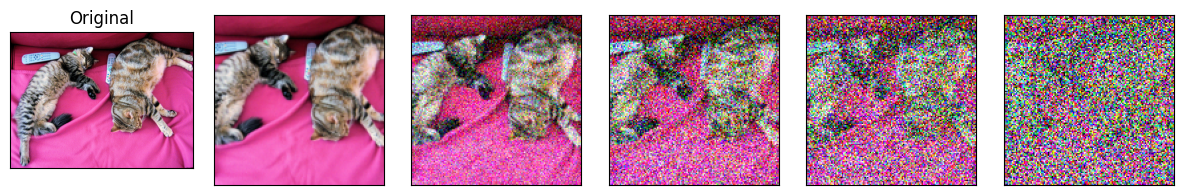

In [7]:
# 7
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
import torch
from torchvision.transforms import Compose, ToTensor, Lambda, CenterCrop, Resize, ToPILImage

# -------------------------------------------------------------------
# 1. 샘플 이미지 준비 및 전처리 (Preprocessing)
# -------------------------------------------------------------------

# 1) 웹에서 이미지 불러오기 (COCO 데이터셋의 고양이 이미지)
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw)

image_size = 128

# 2) 전처리 파이프라인 구성
# Diffusion 모델은 일반적으로 [-1, 1] 범위의 데이터를 사용합니다.
transform = Compose([
    Resize(image_size),           # 짧은 쪽을 128로 조절
    CenterCrop(image_size),       # 중앙을 128x128로 크롭
    ToTensor(),                   # PIL 이미지를 [0, 1] 범위의 텐서로 변환 (C, H, W)
    Lambda(lambda t: (t * 2) - 1),# [0, 1] 범위를 [-1, 1] 범위로 선형 변환
])

# x_start: 원본 이미지(x0). 모델 입력용 배치를 위해 (1, 3, 128, 128)로 확장
x_start = transform(image).unsqueeze(0)

# 3) 역전처리 파이프라인 (모델 출력인 텐서를 다시 눈으로 볼 수 있는 이미지로)
reverse_transform = Compose([
    Lambda(lambda t: (t + 1) / 2),           # [-1, 1] -> [0, 1]
    Lambda(lambda t: t.permute(1, 2, 0)),    # (C, H, W) -> (H, W, C) 순서 변경
    Lambda(lambda t: (t * 255.).clamp(0, 255)), # [0, 1] -> [0, 255] 정규화 및 클리핑
    Lambda(lambda t: t.numpy().astype(np.uint8)), # 텐서를 넘파이(uint8) 배열로 변환
    ToPILImage(),                            # 배열을 다시 PIL 이미지 객체로 변환
])

# -------------------------------------------------------------------
# 2. Forward Diffusion 수식 구현 (q_sample)
# -------------------------------------------------------------------

def q_sample(x_start, t, noise=None):
    """
    수식: q(x_t | x_0) = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * epsilon
    이 수식은 x_0에서 중간 단계 없이 즉시 x_t를 샘플링하게 해줍니다.
    """
    if noise is None:
        # 가우시안 노이즈(epsilon) 생성
        noise = torch.randn_like(x_start)

    # 미리 계산해둔 계수 리스트에서 현재 t에 해당하는 계수를 (B, 1, 1, 1)로 추출
    sqrt_alphas_cumprod_t = extract(sqrt_alphas_cumprod, t, x_start.shape)
    sqrt_one_minus_alphas_cumprod_t = extract(
        sqrt_one_minus_alphas_cumprod, t, x_start.shape
    )

    # 수식 그대로 계산 (원본의 강도는 줄이고, 노이즈의 강도는 키우고)
    return sqrt_alphas_cumprod_t * x_start + sqrt_one_minus_alphas_cumprod_t * noise

def get_noisy_image(x_start, t):
    """특정 타임스텝 t의 노이즈 섞인 이미지를 시각화 가능한 이미지로 반환"""
    x_noisy = q_sample(x_start, t=t)
    return reverse_transform(x_noisy.squeeze()) # 배치 차원을 제거하고 이미지로 변환

# -------------------------------------------------------------------
# 3. 시각화 함수 (여러 단계를 한눈에 비교)
# -------------------------------------------------------------------

def plot(imgs, with_orig=False, row_title=None, **imshow_kwargs):
    """이미지 리스트를 격자 형태로 출력하는 함수"""
    if not isinstance(imgs[0], list):
        imgs = [imgs]

    num_rows = len(imgs)
    num_cols = len(imgs[0]) + (1 if with_orig else 0)

    fig, axs = plt.subplots(
        figsize=(2 * num_cols, 2 * num_rows),
        nrows=num_rows, ncols=num_cols, squeeze=False,
    )

    for row_idx, row in enumerate(imgs):
        row = [image] + row if with_orig else row # 원본 포함 여부
        for col_idx, img in enumerate(row):
            ax = axs[row_idx, col_idx]
            ax.imshow(np.asarray(img), **imshow_kwargs)
            ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

    if with_orig:
        axs[0, 0].set(title="Original")
    if row_title is not None:
        for row_idx in range(num_rows):
            axs[row_idx, 0].set(ylabel=row_title[row_idx])
    plt.tight_layout()

# 실행: 타임스텝 0, 50, 100, 150, 250에서의 변화 시각화
# t가 커질수록(오른쪽으로 갈수록) 이미지가 파괴되어 노이즈로 변하는 과정을 확인하세요.
plot(
    [get_noisy_image(x_start, torch.tensor([t])) for t in [0, 50, 100, 150, 250]],
    with_orig=True
)

## 9. 학습 손실 함수 정의

DDPM의 학습 목표는 **신경망($\theta$)이 이미지에 추가된 노이즈 $\epsilon$을 얼마나 정확하게 예측하는가**를 측정하는 것입니다.

### 학습 알고리즘 단계

1. 데이터셋에서 깨끗한 이미지 $x_0$를 샘플링합니다.
2. 전체 타임스텝 중 임의의 시점 $t \sim \text{Uniform}(1, \dots, T)$를 샘플링합니다.
3. 이미지에 섞을 가우시안 노이즈 $\epsilon \sim \mathcal{N}(0, \mathbf{I})$를 생성합니다.
4. $x_0$와 $\epsilon$을 사용하여 노이즈가 섞인 이미지 $x_t$를 계산합니다.
   $$x_t = \sqrt{\bar{\alpha}_t} x_0 + \sqrt{1-\bar{\alpha}_t} \epsilon$$
5. U-Net 네트워크에 $x_t$와 타임스텝 $t$를 입력하여 예측 노이즈 $\hat{\epsilon}_\theta(x_t, t)$를 얻습니다.
6. 실제 노이즈 $\epsilon$과 예측된 노이즈 $\hat{\epsilon}_\theta$ 사이의 **MSE(L2)** 또는 **Huber Loss**를 최소화합니다.
   $$\mathcal{L} = \| \epsilon - \hat{\epsilon}_\theta(x_t, t) \|^2$$



> 이 과정을 코드로 구현한 것이 `p_losses` 함수이며, 모델은 이 손실 함수를 통해 이미지에서 노이즈 성분만 골라내는 방법을 배우게 됩니다.

### [셀 # 8] 코드 설명

**한 줄 요약:** 학습의 채점 기준인 손실 함수 `p_losses`를 정의합니다. "실제로 섞은 잡음"과 "모델이 예측한 잡음"이 얼마나 다른지를 계산합니다.

**코드 흐름** — 4단계입니다.

1. **정답 잡음 만들기** — `noise = torch.randn_like(x_start)`. 우리가 직접 만든 것이므로 정답을 알고 있습니다.
2. **잡음 섞기** — `x_noisy = q_sample(x_start=x_start, t=t, noise=noise)`. 7번 셀의 함수로 t단계의 그림을 만듭니다.
3. **모델에게 물어보기** — `predicted_noise = denoise_model(x_noisy, t)`. 잡음 섞인 그림과 단계 번호를 주고, 섞인 잡음을 예측하게 합니다.
4. **채점** — `loss_type`에 따라 세 가지 방식 중 하나로 오차를 계산합니다.

| `loss_type` | 함수 | 방식 |
|---|---|---|
| `"l1"` | `F.l1_loss` | 차이의 절댓값 평균 |
| `"l2"` | `F.mse_loss` | 차이의 제곱 평균 |
| `"huber"` | `F.smooth_l1_loss` | 차이가 작을 때는 제곱, 클 때는 절댓값 (두 방식의 절충) |

그 밖의 값이 들어오면 `raise NotImplementedError(...)`로 에러를 냅니다.

**이 학습 방식의 특징:** 사람이 붙인 정답(라벨)이 필요 없습니다. 그림만 있으면 잡음을 직접 섞어 "문제(잡음 섞인 그림)"와 "정답(섞은 잡음)"을 스스로 만들어 낼 수 있기 때문입니다.

**Python 초보 포인트**

- `noise=None`, `loss_type="l1"` 은 기본값입니다. 12번 셀에서는 `loss_type="huber"`로 지정해 부릅니다.
- `if ... elif ... else` : 여러 경우 중 하나를 고르는 구문입니다. 위에서부터 차례로 검사해 처음 맞는 곳만 실행합니다.
- `raise 에러종류("메시지")` : 일부러 에러를 일으켜 프로그램을 멈춥니다. 잘못된 값이 조용히 지나가는 것을 막습니다.
- `q_sample(x_start=x_start, t=t, noise=noise)` : 왼쪽은 함수가 받는 인자 이름, 오른쪽은 내가 가진 변수입니다. 이름이 같을 뿐입니다.
- `denoise_model`은 함수의 인자 이름일 뿐이고, 실제로는 11번 셀에서 만드는 `model`(U-Net)이 들어옵니다.

In [8]:
# 8
import torch.nn.functional as F

def p_losses(denoise_model, x_start, t, noise=None, loss_type="l1"):
    """
    Diffusion 모델을 학습시키기 위한 손실 함수(Loss Function) 계산 함수입니다.
    네트워크(U-Net)가 이미지에 섞인 노이즈를 얼마나 잘 찾아내는지 측정합니다.
    """

    # 1. 실제 노이즈(Ground Truth Noise) 생성
    # 이미지와 동일한 크기의 가우시안 노이즈(epsilon)를 만듭니다.
    if noise is None:
        noise = torch.randn_like(x_start)

    # 2. Forward Diffusion: x_0(원본)에서 x_t(노이즈 섞인 상태) 계산
    # 앞서 정의한 q_sample 함수를 사용하여 t 시점의 노이즈 이미지 x_t를 얻습니다.
    # 수식: x_t = sqrt(alpha_bar_t) * x_start + sqrt(1 - alpha_bar_t) * noise
    x_noisy = q_sample(x_start=x_start, t=t, noise=noise)

    # 3. 모델의 예측
    # U-Net 모델(denoise_model)에 '노이즈 이미지(x_noisy)'와 '타임스텝(t)'을 입력합니다.
    # 모델은 "이 이미지의 이 타임스텝에는 어떤 노이즈가 섞여 있어?"라는 질문에 답합니다.
    predicted_noise = denoise_model(x_noisy, t)

    # 4. 손실(Loss) 계산
    # 실제로 섞은 노이즈(noise)와 모델이 예측한 노이즈(predicted_noise) 사이의 오차를 구합니다.
    if loss_type == "l1":
        # L1 Loss: 오차의 절댓값 평균 (이상치에 상대적으로 강건함)
        loss = F.l1_loss(noise, predicted_noise)
    elif loss_type == "l2":
        # L2 Loss (MSE): 오차의 제곱 평균 (표준적인 DDPM 학습 방식)
        loss = F.mse_loss(noise, predicted_noise)
    elif loss_type == "huber":
        # Huber Loss (Smooth L1): L1과 L2의 장점을 섞은 방식 (학습 안정화에 도움)
        loss = F.smooth_l1_loss(noise, predicted_noise)
    else:
        raise NotImplementedError("지원하지 않는 loss_type입니다.")

    return loss

## 10. Fashion-MNIST 데이터셋 로드 및 전처리

실습에서는 **Hugging Face `fashion_mnist` 데이터셋**을 사용합니다.

- 28x28 grayscale 이미지 (의류/신발 등 10 클래스)
- 여기서는 **레이블은 사용하지 않고**, 오직 이미지 분포만 학습합니다.
- 이미지를 \([-1, 1]\) 범위의 텐서로 변환하고, 간단한 augmentation으로 random horizontal flip을 적용합니다.


### [셀 # 9] 코드 설명

**한 줄 요약:** 학습에 쓸 Fashion-MNIST 데이터(28×28 흑백 옷·신발 그림 6만 장)를 내려받고, 전처리를 붙인 뒤, 128장씩 묶어 꺼내 주는 DataLoader를 만듭니다.

**코드 흐름**

1. `dataset = load_dataset("fashion_mnist")` — Hugging Face에서 데이터셋을 내려받습니다(처음 한 번만). 결과는 `"train"`과 `"test"`로 나뉜 묶음입니다.
2. 설정값: `image_size = 28`, `channels = 1`(흑백), `batch_size = 128`
3. `transform = transforms.Compose([...])` — 전처리 3단계
   - `RandomHorizontalFlip()` : 50% 확률로 좌우 뒤집기(데이터를 다양하게)
   - `ToTensor()` : 0~1 숫자 텐서로
   - `Lambda(lambda t: (t * 2) - 1)` : -1~1 범위로 (7번 셀과 같은 이유)
4. `transform_examples(examples)` — 데이터 묶음에 전처리를 적용하는 함수
   - `examples`는 딕셔너리입니다: `{"image": [그림1, 그림2, ...], "label": [9, 0, ...]}`
   - `[transform(image.convert("L")) for image in examples["image"]]` : 그림마다 흑백(`"L"`)으로 확실히 바꾼 뒤 전처리를 적용해 리스트로 모읍니다.
   - 결과를 `"pixel_values"`라는 새 이름표로 저장하고, 원래의 `"image"`는 `del`로 지웁니다.
5. `transformed_dataset = dataset.with_transform(transform_examples).remove_columns("label")`
   - `with_transform(...)` : "데이터를 꺼낼 때마다 이 함수를 적용하라"고 등록합니다. 미리 전부 변환하지 않고 **꺼내는 순간에** 변환합니다.
   - `remove_columns("label")` : 정답 라벨 열을 제거합니다. 디퓨전 학습에는 필요 없기 때문입니다(8번 셀 참고).
6. `dataloader = DataLoader(transformed_dataset["train"], batch_size=128, shuffle=True, drop_last=True)`
   - `shuffle=True` : 매 epoch마다 순서를 섞습니다.
   - `drop_last=True` : 128장이 안 되는 마지막 자투리 묶음은 버립니다. 60,000 ÷ 128 = 468묶음(나머지 96장은 버림).
7. `batch = next(iter(dataloader))` — 첫 묶음을 꺼내 모양이 `(128, 1, 28, 28)`인지 확인합니다.

**Python 초보 포인트**

- `batch['pixel_values']` : 이 DataLoader가 주는 묶음은 **딕셔너리**입니다. 다른 노트북처럼 `(이미지, 정답)` 튜플이 아니라 이름표로 꺼냅니다.
- `del 딕셔너리["키"]` : 딕셔너리에서 그 항목을 지웁니다.
- `a.b(...).c(...)` : 앞 결과에 이어서 다음 동작을 적용하는 메서드 체이닝입니다.
- 이 셀에서 `transform`과 `image_size`를 **새로 정의**하므로, 7번 셀에서 만든 같은 이름의 변수(고양이 사진용, 128)는 덮어써집니다. 이 셀 이후에 7번 셀을 다시 실행하면 값이 또 바뀌니 순서에 주의하세요.

In [9]:
# 9
# -------------------------------------------------------------------
# 1. Fashion-MNIST 데이터셋 로드
# -------------------------------------------------------------------
# Hugging Face의 datasets 라이브러리를 사용하여 데이터를 불러옵니다.
# 이 데이터셋은 28x28 해상도의 흑백 의류 이미지들로 구성되어 있습니다.
dataset = load_dataset("fashion_mnist")

# 하이퍼파라미터 설정
image_size = 28  # Fashion-MNIST의 기본 크기
channels = 1    # 흑백(Grayscale) 이미지이므로 채널은 1
batch_size = 128

# -------------------------------------------------------------------
# 2. 이미지 전처리(Augmentation & Normalization) 정의
# -------------------------------------------------------------------
transform = transforms.Compose([
    # 좌우 반전을 무작위로 적용하여 데이터의 다양성을 확보합니다.
    transforms.RandomHorizontalFlip(),

    # PIL 이미지를 PyTorch 텐서로 변환하며 값을 [0, 1] 범위로 정규화합니다.
    transforms.ToTensor(),

    # Diffusion 모델의 안정적인 학습을 위해 [0, 1] 범위를 [-1, 1] 범위로 변환합니다.
    # 수식: (0 * 2) - 1 = -1, (1 * 2) - 1 = 1
    transforms.Lambda(lambda t: (t * 2) - 1),
])

# -------------------------------------------------------------------
# 3. 데이터셋 변환 함수 정의 (Hugging Face 전용)
# -------------------------------------------------------------------
def transform_examples(examples):
    """
    Hugging Face 데이터셋의 각 샘플에 전처리를 적용하는 함수입니다.
    """
    # 1. 원본 'image' 열에서 이미지를 꺼내 'L'(흑백) 모드로 확실히 변환 후 전처리 적용
    # 2. 전처리된 결과를 'pixel_values'라는 새로운 키에 리스트 형태로 저장
    #    - 변환 전 : {"image": [PIL객체1, PIL객체2, ...], "label": [9, 0, ...]}
    #    - 변환 후 : {"pixel_values": [텐서1, 텐서2, ...], "image": [PIL객체1, PIL객체2, ...], "label": [9, 0, ...]}
    examples["pixel_values"] = [transform(image.convert("L")) for image in examples["image"]]

    # 메모리 절약을 위해 원본 이미지 데이터는 삭제합니다.
    del examples["image"]
    return examples

# 데이터셋에 변환 함수를 등록하고, 사용하지 않는 'label' 열은 제거합니다.
# (이 실습은 비지도 학습인 Diffusion이므로 레이블이 필요 없습니다.)
transformed_dataset = dataset.with_transform(transform_examples).remove_columns("label")

# -------------------------------------------------------------------
# 4. DataLoader 구축 (Batch 생성)
# -------------------------------------------------------------------
# 실제 학습 루프에서 데이터를 효율적으로 공급하기 위해 DataLoader를 사용합니다.
dataloader = DataLoader(
    transformed_dataset["train"],
    batch_size=batch_size,
    shuffle=True,  # 매 에포크마다 데이터를 섞어 학습 성능을 높입니다.
    drop_last=True # 배치 사이즈에 맞지 않는 마지막 자투리 데이터는 버립니다.
)

# 데이터 로드가 잘 되었는지 첫 번째 배치를 확인해봅니다.
batch = next(iter(dataloader))
# 결과 출력: (배치 사이즈, 채널, 높이, 너비) -> (128, 1, 28, 28)
print(f"Batch shape: {batch['pixel_values'].shape}")

Using the latest cached version of the dataset since fashion_mnist couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'fashion_mnist' at C:\Users\bioyo\.cache\huggingface\datasets\fashion_mnist\fashion_mnist\0.0.0\531be5e2ccc9dba0c201ad3ae567a4f3d16ecdd2 (last modified on Thu May  7 14:02:23 2026).


Batch shape: torch.Size([128, 1, 28, 28])


## 11. Reverse Diffusion (Sampling) 정의

이제 학습이 끝났다고 가정하고, **아무것도 없는 노이즈(Pure Noise)에서 시작해서 이미지를 생성하는 과정**을 정의합니다.

### 11.1 한 스텝 샘플링: `p_sample`

현재 단계의 이미지 $x_t$에서 이전 단계의 이미지 $x_{t-1}$를 추론하는 과정은 다음과 같은 확률 분포를 따릅니다.

$$p_\theta(x_{t-1} \mid x_t) = \mathcal{N}(x_{t-1}; \mu_\theta(x_t, t), \sigma_t^2 \mathbf{I})$$

- 여기서 $\mu_\theta$는 네트워크가 예측한 **노이즈($\hat{\epsilon}_\theta$)**를 이용하여 계산된 평균입니다.
- $\sigma_t^2$는 미리 정의된 노이즈의 분산입니다.
- 모델은 한 번에 이미지를 완성하는 것이 아니라, $x_t$에서 노이즈 성분을 살짝 제거하여 조금 더 선명한 $x_{t-1}$을 만듭니다.

### 11.2 전체 샘플링 루프 (Reverse Process)

전체 생성 과정은 다음과 같은 순서로 진행됩니다.

1. **시작**: 완전히 무작위인 노이즈 $x_T \sim \mathcal{N}(0, \mathbf{I})$에서 시작합니다.
2. **반복**: $t = T-1, T-2, \dots, 0$까지 거꾸로 거슬러 올라가며 `p_sample`을 적용합니다.
3. **완성**: 최종적으로 노이즈가 모두 제거된 깨끗한 이미지 샘플 $x_0$를 얻습니다.



> **핵심 포인트:** 학습할 때는 노이즈를 **입히는 법**($\epsilon$)을 배웠지만, 생성할 때는 배운 지식을 활용해 노이즈를 **걷어내는 법**을 실행하는 것입니다.

### [셀 # 10] 코드 설명

**한 줄 요약:** 학습된 모델로 **잡음에서 그림을 만들어 내는** 함수 3개를 정의합니다 — 한 단계 되돌리기(`p_sample`), 처음부터 끝까지 반복(`p_sample_loop`), 간편 호출용(`sample`). 정의만 하고 실행은 12, 13번 셀에서 합니다.

**코드 흐름 ① `p_sample(model, x, t, t_index)` — 한 단계 깨끗하게**

지금의 그림 `x`(t단계)에서 한 단계 덜 잡음 낀 그림(t-1단계)을 계산합니다.

1. `extract(...)` 로 t에 해당하는 계수 3개를 꺼냅니다(6번 셀에서 미리 계산한 값).
2. `model_mean = sqrt_recip_alphas_t * (x - betas_t * model(x, t) / sqrt_one_minus_alphas_cumprod_t)`
   - `model(x, t)` : 모델이 예측한 잡음
   - 말로 풀면 "**현재 그림에서, 예측한 잡음을 적당한 비율로 빼고, 크기를 보정한다**"입니다.
3. `if t_index == 0:` 마지막 단계면 그 결과를 그대로 돌려줍니다.
4. `else:` 그 밖의 단계에서는 `model_mean + torch.sqrt(posterior_variance_t) * noise` — 새 잡음을 **조금 다시 더합니다.** 잡음을 빼는 과정에 약간의 무작위성을 넣어야 다양한 그림이 자연스럽게 만들어지기 때문입니다.

**코드 흐름 ② `p_sample_loop(model, shape)` — T부터 0까지 반복**

1. `device = next(model.parameters()).device` : 모델이 올라가 있는 장치를 알아냅니다.
2. `img = torch.randn(shape, device=device)` : **완전한 잡음**에서 출발합니다.
3. `for i in tqdm(reversed(range(0, timesteps)), ...)` : i를 299, 298, …, 0으로 **거꾸로** 돌립니다. `tqdm`이 진행 막대를 보여 줍니다.
   - `torch.full((b,), i, device=device, dtype=torch.long)` : 길이 b인 텐서를 전부 i로 채웁니다. 배치의 모든 그림이 같은 단계에 있다는 뜻입니다.
   - `img = p_sample(model, img, 그 텐서, i)` : 한 단계 깨끗하게
   - `imgs.append(img.cpu().numpy())` : 매 단계의 결과를 저장합니다(14번 셀의 애니메이션용).
4. `return imgs` : 300개짜리 리스트. `imgs[0]`은 거의 잡음, `imgs[-1]`이 **최종 완성본**입니다.

**코드 흐름 ③ `sample(model, image_size, batch_size=16, channels=1)`**

원하는 장수와 크기만 주면 `shape=(batch_size, channels, image_size, image_size)`를 만들어 ②를 부르는 편의 함수입니다.

**Python 초보 포인트**

- 함수 위의 `@torch.no_grad()` : 이 함수가 실행되는 동안 학습용 기울기 계산을 끕니다(그림 생성은 학습이 아니므로). 이런 표시를 데코레이터라고 합니다.
- `reversed(range(0, 300))` : 0~299를 거꾸로(299부터 0까지) 꺼냅니다.
- `shape[0]` : 튜플의 첫 번째 값(배치 크기).
- `(b,)` : 원소가 하나인 튜플. 쉼표가 꼭 있어야 합니다.
- `next(model.parameters())` : 모델의 가중치 중 첫 번째 하나만 꺼냅니다.
- 그림 한 묶음을 만들려면 모델을 **300번** 실행해야 합니다. 디퓨전 모델의 생성이 느린 이유입니다.

In [10]:
# 10
import torch
from tqdm.auto import tqdm

# -------------------------------------------------------------------
# 1. p_sample: 현재 단계(t)에서 이전 단계(t-1)의 이미지를 추론
# -------------------------------------------------------------------
@torch.no_grad() # 샘플링 시에는 그래디언트 계산이 필요 없으므로 메모리를 절약합니다.
def p_sample(model, x, t, t_index):
    """
    노이즈가 섞인 이미지 x에서 모델이 예측한 노이즈를 빼서
    조금 더 깨끗한 이전 단계의 이미지를 계산합니다.
    """
    # 현재 타임스텝 t에 해당하는 미리 계산된 계수들을 가져옵니다.
    betas_t = extract(betas, t, x.shape)
    sqrt_one_minus_alphas_cumprod_t = extract(
        sqrt_one_minus_alphas_cumprod, t, x.shape
    )
    sqrt_recip_alphas_t = extract(sqrt_recip_alphas, t, x.shape)

    # [수식 구현] DDPM 논문의 Equation 11: 모델이 예측한 평균(mu) 계산
    # '현재 이미지'에서 '모델이 예측한 노이즈' 성분을 적절한 비율로 빼주는 과정입니다.
    # model(x, t)는 U-Net이 예측한 노이즈(epsilon_theta)입니다.
    model_mean = sqrt_recip_alphas_t * (
        x - betas_t * model(x, t) / sqrt_one_minus_alphas_cumprod_t
    )

    if t_index == 0:
        # 마지막 단계(t=0)라면 평균값을 그대로 반환하여 최종 이미지를 얻습니다.
        return model_mean
    else:
        # t > 0 이라면 계산된 평균에 약간의 무작위 노이즈를 더해줍니다.
        # 이 과정이 있어야 Langevin Dynamics처럼 확률적으로 데이터 분포를 찾아갑니다.
        posterior_variance_t = extract(posterior_variance, t, x.shape)
        noise = torch.randn_like(x) # epsilon ~ N(0, I)

        # 평균 + 표준편차 * 노이즈
        return model_mean + torch.sqrt(posterior_variance_t) * noise

# -------------------------------------------------------------------
# 2. p_sample_loop: T부터 0까지 반복하여 이미지 생성
# -------------------------------------------------------------------
@torch.no_grad()
def p_sample_loop(model, shape):
    """
    완전한 노이즈에서 시작하여 타임스텝을 거꾸로 거슬러 올라가며
    최종 이미지를 생성하는 전체 루프입니다.
    """
    device = next(model.parameters()).device
    b = shape[0] # 배치 사이즈

    # 1. 시작점: 완전한 가우시안 노이즈 x_T 생성 (Pure Noise)
    img = torch.randn(shape, device=device)
    imgs = [] # 변화 과정을 저장할 리스트

    # 2. 역과정 반복: T-1부터 0까지 거꾸로 진행 (Reverse Process)
    # tqdm을 사용하여 샘플링 진행 상황을 시각적으로 표시합니다.
    for i in tqdm(reversed(range(0, timesteps)), desc="sampling loop time step", total=timesteps):
        # p_sample 함수를 호출하여 한 단계 더 깨끗한 이미지를 얻음
        img = p_sample(
            model,
            img,
            torch.full((b,), i, device=device, dtype=torch.long), # 현재 타임스텝 t를 텐서로 전달
            i,
        )
        # 나중에 애니메이션이나 시각화를 위해 결과 저장
        imgs.append(img.cpu().numpy())

    return imgs

# -------------------------------------------------------------------
# 3. sample: 사용자용 최종 호출 함수
# -------------------------------------------------------------------
@torch.no_grad()
def sample(model, image_size, batch_size=16, channels=1):
    """
    외부에서 간편하게 이미지를 생성할 때 사용하는 함수입니다.
    원하는 이미지 크기와 배치 사이즈를 정하면 생성된 이미지 리스트를 반환합니다.
    """
    return p_sample_loop(model, shape=(batch_size, channels, image_size, image_size))

## 12. 모델, Optimizer, 결과 저장 폴더 설정

이제까지 정의한 U-Net과 손실 함수를 이용하여 **실제 학습 루프를 돌릴 준비**를 합니다.

- base dimension: `image_size` (28) 을 그대로 사용
- `dim_mults`: `(1, 2, 4)` 로 해서 U-Net 깊이를 적당히 설정
- Optimizer: Adam, learning rate = 1e-3


### [셀 # 11] 코드 설명

**한 줄 요약:** 학습 준비를 마칩니다 — 결과를 저장할 폴더를 만들고, U-Net 모델과 옵티마이저를 생성하고, 모델의 크기(파라미터 수)를 확인합니다.

**코드 흐름**

1. `results_folder = Path("./results_ddpm")` — 저장 폴더 경로. `results_folder.mkdir(exist_ok=True)`는 폴더를 만들되, 이미 있어도 에러를 내지 않습니다.
2. `save_and_sample_every = 400` — 학습 중 400스텝마다 그림을 만들어 저장하겠다는 설정입니다.
3. `model = Unet(dim=image_size, channels=channels, dim_mults=(1, 2, 4), resnet_block_groups=4)` — 5번 셀의 설계도로 모델을 만듭니다.
   - `dim=28` : **기본 채널 수**입니다. 값으로 `image_size`(28)를 넣었을 뿐, 이미지 크기를 뜻하는 것은 아닙니다.
   - `channels=1` : 흑백 입력
   - `dim_mults=(1, 2, 4)` : 단계별 채널이 28 → 56 → 112
   - `resnet_block_groups=4` : GroupNorm의 그룹 수
4. `model = model.to(device)` — 모델을 GPU(또는 CPU)로 옮깁니다.
5. `optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)` — Adam 옵티마이저, 학습률 0.001
6. `print("Model parameters:", sum(p.numel() for p in model.parameters()))` — 모델 안의 학습되는 숫자가 모두 몇 개인지 출력합니다.

**Python 초보 포인트**

- `Path("...")` 는 경로를 다루는 객체입니다. 12번 셀의 `results_folder / "파일이름"` 처럼 `/` 기호로 경로를 이어 붙일 수 있어 편리합니다.
- `sum(p.numel() for p in model.parameters())` : 가중치 텐서를 하나씩 꺼내(`for p in ...`) 각각의 숫자 개수(`p.numel()`)를 모두 더합니다.
- `1e-3` 은 0.001입니다.
- `(1, 2, 4)` 는 튜플입니다.

**알아둘 점:** `dim` 옆의 코드 주석은 "특징 맵의 크기"라고 되어 있지만, 5번 셀에서 본 것처럼 실제로는 채널 수의 기준값으로 쓰입니다. 예컨대 `dim=32`나 `dim=64`로 바꾸면 이미지 크기와 무관하게 모델이 더 커집니다(단, `resnet_block_groups`로 나누어떨어지는 값이어야 합니다).

In [11]:
# 11
# -------------------------------------------------------------------
# 1. 결과 저장 경로 설정
# -------------------------------------------------------------------
# 학습 중간에 생성된 샘플 이미지와 모델 체크포인트를 저장할 폴더를 지정합니다.
results_folder = Path("./results_ddpm")
results_folder.mkdir(exist_ok=True) # 폴더가 없으면 생성하고, 있으면 그대로 사용합니다.

# 400 step마다 현재 모델의 성능을 확인하기 위해 이미지를 생성(Sampling)하고 저장합니다.
save_and_sample_every = 400

# -------------------------------------------------------------------
# 2. U-Net 모델 선언
# -------------------------------------------------------------------
# Diffusion의 핵심 두뇌인 U-Net 신경망을 생성합니다.
model = Unet(
    dim=image_size,           # 기본 특징 맵(Feature map)의 크기 (Fashion-MNIST의 경우 28)
    channels=channels,        # 입력 이미지의 채널 수 (흑백이므로 1)
    dim_mults=(1, 2, 4),      # Downsampling을 진행하며 채널 수를 몇 배씩 늘릴지 결정 (1배 -> 2배 -> 4배)
    resnet_block_groups=4,    # Group Normalization에 사용될 그룹 수 (학습 안정화에 도움)
)

# 모델을 GPU(device)로 이동시켜 연산 속도를 높입니다.
model = model.to(device)

# -------------------------------------------------------------------
# 3. 최적화 도구(Optimizer) 설정
# -------------------------------------------------------------------
# 모델의 가중치를 업데이트할 알고리즘으로 Adam을 사용합니다.
# lr=1e-3 (0.001)은 모델이 한 번에 얼마나 크게 학습할지를 결정하는 학습률입니다.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# -------------------------------------------------------------------
# 4. 모델 규모 확인
# -------------------------------------------------------------------
# 전체 모델의 파라미터(가중치) 개수를 출력하여 모델의 크기를 가늠합니다.
# numel()은 각 텐서의 요소 개수를 반환합니다.
print("Model parameters:", sum(p.numel() for p in model.parameters()))

Model parameters: 2020257


## 13. 학습 루프 구현

### 13.1 학습 절차

각 minibatch 에 대해 다음을 수행합니다.

1. 이미지 배치 \(x_0\) 를 로드
2. 각 샘플마다 time step \(t \sim \mathcal{U}({0, \dots, T-1})\) 를 샘플링
3. `p_losses` 를 통해 loss를 계산
4. 역전파 및 optimizer step
5. 일정 step마다 `sample` 함수를 호출하여 중간 결과 이미지 저장



### [셀 # 12] 코드 설명

**한 줄 요약:** 실제 학습을 실행합니다. 10 epoch 동안 "잡음 섞기 → 잡음 예측 → 오차만큼 모델 수정"을 반복하고, 400스텝마다 그림을 생성해 파일로 저장합니다.

**코드 흐름 ① 학습 (바깥 틀)**

1. `for epoch in range(epochs):` — 10번 반복. `model.train()`으로 학습 모드로 둡니다.
2. `for step, batch in enumerate(dataloader):` — 128장씩 묶음을 꺼냅니다(한 epoch에 468번).
3. 묶음 하나에 대한 학습

| 코드 | 하는 일 |
|---|---|
| `optimizer.zero_grad()` | 이전 묶음의 기울기를 지움 |
| `batch_imgs = batch["pixel_values"].to(device)` | 이미지를 꺼내 장치로 옮김. `b = batch_imgs.shape[0]`은 장수(128) |
| `t = torch.randint(0, timesteps, (b,), device=device, dtype=torch.long)` | 이미지마다 0~299 중 **무작위 단계** 하나씩 뽑음 |
| `loss = p_losses(model, batch_imgs, t, loss_type="huber")` | 8번 셀의 함수: 잡음 섞기 → 예측 → 오차 계산 |
| `loss.backward()` | 가중치별로 고칠 방향 계산 |
| `optimizer.step()` | 가중치 수정 |

4. `if step % 100 == 0:` — 100스텝마다 loss를 출력합니다.

**왜 t를 무작위로 뽑나?** 모델은 잡음이 조금 섞인 그림부터 잡음투성이 그림까지 **모든 단계**를 다룰 줄 알아야 합니다. 매번 무작위 단계를 연습시키면 전 단계를 골고루 배우게 됩니다.

**코드 흐름 ② 중간 점검 — `if step != 0 and step % save_and_sample_every == 0:`**

스텝이 400의 배수일 때 실행됩니다(한 epoch이 468스텝이므로 epoch마다 한 번).

1. `was_training = model.training` 으로 현재 모드를 기억하고 `model.eval()`로 전환합니다.
2. `groups = num_to_groups(num=4, divisor=b)` → `[4]`. 4장을 만들겠다는 뜻입니다.
3. `sample(model, image_size=image_size, batch_size=n, channels=channels)[-1]` — 10번 셀의 함수로 그림을 생성하고, 300단계 결과 중 **마지막(완성본)** 만 가져옵니다.
4. `np.concatenate(...)` 로 합치고, `torch.from_numpy(...).float()`로 텐서로 바꿉니다.
5. `((all_images + 1) * 0.5).clamp(0, 1)` — -1~1 범위를 0~1로 되돌립니다.
6. `save_image(all_images, save_path, nrow=4)` — 4장을 한 줄로 이어 붙인 그림 파일로 저장합니다.
7. `if was_training: model.train()` — 학습 모드로 복귀합니다.

**보는 법:** `results_ddpm` 폴더에 `sample-epoch1-...png`, `sample-epoch2-...png` … 가 차례로 생깁니다. 초반 파일은 얼룩 같지만, epoch이 진행될수록 옷·신발 모양이 뚜렷해집니다.

**Python 초보 포인트**

- `step % 100 == 0` : step을 100으로 나눈 나머지가 0, 즉 100의 배수일 때 참입니다.
- `A and B` : 둘 다 참이어야 참입니다. `step != 0`은 맨 처음(0번)을 제외하려는 조건입니다.
- `[... for n in groups]` : 리스트 컴프리헨션.
- `[-1]` : 리스트의 마지막 항목.
- `results_folder / f"sample-epoch{epoch+1}-..."` : Path 객체는 `/`로 경로를 이어 붙입니다. `str(...)`로 문자열로 바꿔 넘깁니다.
- `f"{step:05d}"` : 5자리로 맞추고 빈자리는 0으로 채웁니다(예: `00100`).
- `range(epochs)` 는 0부터 시작하므로, 사람이 읽기 좋게 `epoch + 1`로 출력합니다.

**알아둘 점:** GPU가 없으면 매우 오래 걸립니다. 맛보기로만 돌리려면 `epochs = 1`로 줄이세요. 중간 점검 때마다 모델을 300번 실행하므로 그 순간에는 잠시 멈춘 것처럼 보일 수 있습니다.

In [12]:
# 12
# -------------------------------------------------------------------
# DDPM 메인 학습 루프
# -------------------------------------------------------------------

epochs = 10  # 전체 데이터셋을 몇 번 반복해서 학습할지 설정

for epoch in range(epochs):
    model.train()
    print(f"Epoch {epoch + 1}/{epochs}")

    # DataLoader를 통해 배치 단위로 데이터를 가져옵니다.
    for step, batch in enumerate(dataloader):
        # 1. 변화도(Gradient) 초기화: 이전 루프의 기울기 값을 비웁니다.
        optimizer.zero_grad()

        # 현재 배치의 이미지 개수 확인 및 데이터를 GPU로 전송
        batch_imgs = batch["pixel_values"].to(device)
        b = batch_imgs.shape[0]

        # 2. 타임스텝(t) 샘플링: 배치 내 각 이미지마다 서로 다른 t를 무작위로 선택합니다.
        t = torch.randint(0, timesteps, (b,), device=device, dtype=torch.long)

        # 3. 손실 함수 계산: p_losses 함수 내에서 노이즈 주입(Forward) 및 노이즈 예측이 일어납니다.
        # 여기서는 오차에 강건한 'huber' loss를 사용합니다.
        loss = p_losses(model, batch_imgs, t, loss_type="huber")

        # 100 step마다 현재 학습 손실(Loss)을 출력하여 모니터링합니다.
        if step % 100 == 0:
            print(f"   Step {step:05d} | Loss: {loss.item():.4f}")

        # 4. 역전파(Backpropagation): 손실값으로부터 가중치별 기울기를 계산합니다.
        loss.backward()

        # 5. 가중치 업데이트: 계산된 기울기를 바탕으로 optimizer가 모델의 파라미터를 수정합니다.
        optimizer.step()

        # ---- sampling & save ----
        if step != 0 and step % save_and_sample_every == 0:
            milestone = step // save_and_sample_every

            was_training = model.training
            model.eval()

            # 생성할 이미지 개수(4개)를 배치 사이즈에 맞게 그룹화합니다.
            # (예: 4개를 생성해야 하는데 배치가 128이면 [4]라는 리스트 생성)
            groups = num_to_groups(num=4, divisor=b)

            # 학습 중인 모델을 사용하여 실제 이미지를 생성해봅니다 (Reverse Diffusion).
            # sample() 함수의 결과 중 마지막 단계([-1])인 x_0를 가져옵니다.            
            all_images_list = [
                sample(model, image_size=image_size, batch_size=n, channels=channels)[-1]
                for n in groups
            ]

            # 리스트에 담긴 넘파이 배열들을 하나로 합치고 텐서로 변환합니다.
            all_images = np.concatenate(all_images_list, axis=0)     # (4,1,28,28) numpy
            all_images = torch.from_numpy(all_images).float()        # torch float32 CPU
            # 후처리: 시각화를 위해 [-1, 1] 범위를 다시 [0, 1] 범위로 되돌립니다.
            all_images = ((all_images + 1) * 0.5).clamp(0, 1)        # [0,1]

            # 생성된 이미지를 파일로 저장하여 학습 진행 상황을 눈으로 확인합니다.
            save_path = str(results_folder / f"sample-epoch{epoch+1}-step{step}-milestone{milestone}.png")
            save_image(all_images, save_path, nrow=4)
            print(f"   [Saved] {save_path}")

            if was_training:
                model.train()



Epoch 1/10
   Step 00000 | Loss: 0.5331
   Step 00100 | Loss: 0.0727
   Step 00200 | Loss: 0.0485
   Step 00300 | Loss: 0.0450
   Step 00400 | Loss: 0.0516


sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

   [Saved] results_ddpm\sample-epoch1-step400-milestone1.png
Epoch 2/10
   Step 00000 | Loss: 0.0388
   Step 00100 | Loss: 0.0339
   Step 00200 | Loss: 0.0433
   Step 00300 | Loss: 0.0364
   Step 00400 | Loss: 0.0337


sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

   [Saved] results_ddpm\sample-epoch2-step400-milestone1.png
Epoch 3/10
   Step 00000 | Loss: 0.0405
   Step 00100 | Loss: 0.0310
   Step 00200 | Loss: 0.0309
   Step 00300 | Loss: 0.0367
   Step 00400 | Loss: 0.0383


sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

... (11 outputs left out)

sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

   [Saved] results_ddpm\sample-epoch9-step400-milestone1.png
Epoch 10/10
   Step 00000 | Loss: 0.0292
   Step 00100 | Loss: 0.0304
   Step 00200 | Loss: 0.0318
   Step 00300 | Loss: 0.0401
   Step 00400 | Loss: 0.0314


sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

   [Saved] results_ddpm\sample-epoch10-step400-milestone1.png


## 14. 학습 후 샘플링 및 시각화

학습이 완료된 후, **모델이 학습한 분포에서 샘플을 생성**해 봅니다.

1. `sample` 함수를 이용해 노이즈에서부터 T step reverse diffusion
2. 최종 결과 \(x_0\) 를 가져와 시각화
3. 랜덤 샘플 몇 개를 그레이스케일 이미지로 표시


### [셀 # 13] 코드 설명

**한 줄 요약:** 학습이 끝난 모델로 새 그림 64장을 생성하고, 그중 무작위로 3장을 골라 화면에 보여 줍니다.

**코드 흐름**

1. `samples = sample(model, image_size=image_size, batch_size=64, channels=channels)` — 10번 셀의 함수로 64장을 한꺼번에 생성합니다. 진행 막대가 300단계를 표시합니다.
   - `samples`는 **300개짜리 리스트**이고, 각 항목은 그 단계에서의 64장 `(64, 1, 28, 28)`입니다.
2. `final_samples = samples[-1]` — 마지막 단계, 즉 완성된 그림들을 꺼냅니다.
3. `final_samples_t = torch.tensor(final_samples)` — numpy 배열을 텐서로 바꿉니다.
4. `final_samples_t = (final_samples_t + 1) * 0.5` — -1~1 범위를 0~1로 되돌립니다.
5. `random_indices = random.sample(range(64), num_to_show)` — 0~63 중 **겹치지 않게** 3개의 번호를 뽑습니다.
6. `fig, axes = plt.subplots(1, num_to_show, figsize=(12, 4))` — 1줄×3칸 격자를 만듭니다.
7. `for i, idx in enumerate(random_indices):` — 칸마다
   - `final_samples_t[idx].reshape(image_size, image_size)` : `(1, 28, 28)` → `(28, 28)`로 바꿔 2차원 그림으로
   - `axes[i].imshow(..., cmap="gray")` : 흑백으로 그리기
   - `axes[i].set_title(...)`, `axes[i].axis("off")` : 제목, 눈금 숨기기
8. `plt.tight_layout()`, `plt.show()`

**보는 법:** 여기 나온 그림은 데이터셋에 **원래 있던 그림이 아니라** 모델이 잡음에서 새로 만들어 낸 것입니다. 티셔츠, 바지, 신발, 가방 같은 형태가 알아볼 수 있게 나오면 학습이 잘 된 것입니다.

**Python 초보 포인트**

- `import random` 처럼 import는 셀 중간에 있어도 됩니다.
- `random.sample(목록, k)` : 목록에서 k개를 중복 없이 무작위로 뽑습니다. 실행할 때마다 결과가 달라집니다.
- `samples[-1]` : 리스트의 마지막 항목.
- `enumerate(random_indices)` : `i`는 칸 번호(0, 1, 2), `idx`는 뽑힌 그림 번호입니다.
- 이 셀에서 만든 `samples`는 다음 14번 셀에서 다시 쓰입니다.

sampling loop time step:   0%|          | 0/300 [00:00<?, ?it/s]

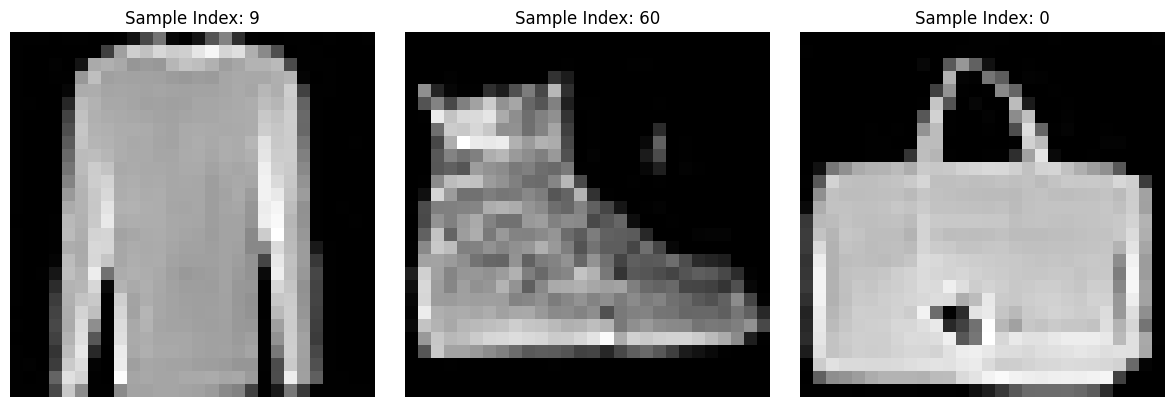

In [13]:
# 13
# -------------------------------------------------------------------
# 1. 이미지 샘플링 실행
# -------------------------------------------------------------------
# 학습된 U-Net 모델을 사용하여 64장의 이미지를 동시에 생성합니다.
# samples는 리스트 형태이며, 각 원소는 [T-1, T-2, ..., 0] 단계의 이미지들입니다.
samples = sample(
    model,
    image_size=image_size,
    batch_size=64,
    channels=channels,
)

# -------------------------------------------------------------------
# 2. 결과물 선택 및 후처리
# -------------------------------------------------------------------
# samples[-1]은 가장 마지막 단계(t=0)인 최종 완성본입니다. -> (64, 1, 28, 28)
final_samples = samples[-1]

# 넘파이(numpy) 배열 형태인 결과를 연산을 위해 파이토치 텐서로 변환합니다.
final_samples_t = torch.tensor(final_samples)

# 모델의 출력 범위인 [-1, 1]을 시각화 가능한 범위인 [0, 1]로 조정합니다.
final_samples_t = (final_samples_t + 1) * 0.5


# -------------------------------------------------------------------
# 3. 무작위 3장 선택 및 시각화
# -------------------------------------------------------------------
# 0~63 사이의 인덱스 중 중복 없이 3개를 무작위로 뽑습니다.
import random
num_to_show = 3
random_indices = random.sample(range(64), num_to_show)

# 1행 3열의 서브플롯 생성
fig, axes = plt.subplots(1, num_to_show, figsize=(12, 4))

for i, idx in enumerate(random_indices):
    # 이미지 데이터를 (1, 28, 28)에서 (28, 28)로 리셰이프하여 2차원 평면으로 만듭니다.
    axes[i].imshow(
        final_samples_t[idx].reshape(image_size, image_size),
        cmap="gray"  # Fashion-MNIST이므로 흑백 지도를 사용합니다.
    )
    axes[i].set_title(f"Sample Index: {idx}") # 몇 번째 이미지인지 표시
    axes[i].axis("off") # 축 숨기기

plt.tight_layout()
plt.show()

## 15. Denoising 과정 GIF로 만들기 (선택)

마지막으로, 한 샘플에 대해 \(x_T \to x_0\) 로 점점 **노이즈가 제거되는 과정**을 GIF 로 저장해 볼 수 있습니다.

> 이 부분은 강의에서 “모든 step의 중간 결과”를 직관적으로 보여줄 때 매우 유용합니다.


### [셀 # 14] 코드 설명

**한 줄 요약:** 잡음이 걷히며 그림이 나타나는 300단계의 과정을 **움직이는 그림(GIF)** 으로 만들어 저장하고 화면에 보여 줍니다.

**코드 흐름**

1. import — `matplotlib.animation`(애니메이션 도구), `PillowWriter`(GIF 저장 도구), `IPyImage`(노트북에 이미지 파일을 표시하는 도구. 앞에서 쓴 PIL의 `Image`와 이름이 겹치지 않게 별명을 붙였습니다.)
2. `random_index = 0` — 64장 중 몇 번째 그림의 과정을 볼지 정합니다. 0~63 사이로 바꿀 수 있습니다.
3. `fig = plt.figure()`, `ims = []` — 도화지와, 프레임(장면)을 담을 빈 리스트
4. `for i in range(timesteps):` — 300단계 각각에 대해
   - `img = samples[i][random_index].reshape(image_size, image_size)` : i번째 단계의, 선택한 그림을 `(28, 28)`로
   - `im = plt.imshow(img, cmap="gray", animated=True)` : 한 장면을 그립니다.
   - `ims.append([im])` : 장면을 리스트에 쌓습니다.
5. `ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=1000)` — 장면들을 이어 애니메이션으로 만듭니다.
   - `interval=50` : 장면 사이 간격 50밀리초
   - `repeat_delay=1000` : 끝난 뒤 1초 쉬고 반복
6. `gif_path = results_folder / "diffusion_process.gif"` — 저장 경로
7. `ani.save(str(gif_path), writer=PillowWriter(fps=20))` — 초당 20장면으로 GIF 저장. 300장면이므로 약 15초 길이입니다.
8. `plt.close(fig)` — 도화지를 닫습니다. 닫지 않으면 GIF와 별도로 마지막 장면 그림이 셀 아래에 한 번 더 출력됩니다.
9. `display(IPyImage(filename=str(gif_path)))` — 저장한 GIF를 화면에 표시합니다.

**보는 법:** 처음에는 지직거리는 잡음뿐이다가, 뒤로 갈수록 형태가 서서히 드러납니다. 대부분의 변화는 **마지막 구간**에서 급격히 일어납니다.

**Python 초보 포인트**

- `samples[i][random_index]` : 두 단계로 꺼냅니다. `samples[i]`는 i번째 단계의 64장, 거기서 `[random_index]`번째 한 장.
- `ims.append([im])` 에서 `[im]`처럼 리스트로 한 번 감싸는 이유: 애니메이션 도구가 "한 장면 = 그려진 요소들의 리스트" 형식을 요구하기 때문입니다.
- `display(...)` 는 따로 import 하지 않았지만 주피터 노트북에서는 기본으로 쓸 수 있습니다. 일반 `.py` 파일로 옮길 때는 `from IPython.display import display`가 필요합니다.
- 이 셀은 13번 셀의 `samples`를 사용합니다. 13번 셀을 먼저 실행해야 합니다.

In [ ]:
# 14
import matplotlib.animation as animation
from matplotlib.animation import PillowWriter
from IPython.display import Image as IPyImage

# -------------------------------------------------------------------
# 1. 애니메이션 설정 및 프레임 생성
# -------------------------------------------------------------------
# 64장의 생성 결과 중 애니메이션으로 보고 싶은 이미지의 인덱스를 선택합니다.
random_index = 0
fig = plt.figure()
ims = []

# 전체 타임스텝(T) 동안의 변화 과정을 하나씩 이미지(프레임)로 만듭니다.
for i in range(timesteps):
    # i번째 타임스텝의 결과물 중 random_index번째 이미지를 가져와 2차원으로 변환
    img = samples[i][random_index].reshape(image_size, image_size)

    # [0, 1] 범위로 정규화하여 출력 (samples가 이미 전처리되어 있다면 그대로 사용)
    # plt.imshow를 실행하고 'animated=True' 설정을 통해 애니메이션용 객체로 저장합니다.
    im = plt.imshow(img, cmap="gray", animated=True)

    # 각 프레임을 리스트에 차곡차곡 쌓습니다.
    ims.append([im])

# -------------------------------------------------------------------
# 2. ArtistAnimation 생성
# -------------------------------------------------------------------
# interval: 프레임 간의 간격 (ms 단위, 50ms = 0.05초)
# blit: 성능 최적화 옵션 (True 설정 시 변경된 부분만 다시 그림)
ani = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=1000)

# -------------------------------------------------------------------
# 3. GIF 파일 저장 및 출력
# -------------------------------------------------------------------
# 결과를 저장할 경로 지정
gif_path = results_folder / "diffusion_process.gif"

# PillowWriter를 사용하여 GIF로 저장합니다. fps는 초당 프레임 수를 의미합니다.
ani.save(str(gif_path), writer=PillowWriter(fps=20))

# 저장이 끝난 후 불필요해진 figure 객체를 닫아 메모리를 관리합니다.
plt.close(fig)

# 생성된 GIF 파일을 주피터 노트북 화면에 즉시 표시합니다.
display(IPyImage(filename=str(gif_path)))